# DermaLens — Unified Training Notebook
**GPU:** RTX 3050 Laptop (6 GB VRAM) | **Run:** Kernel → Restart & Run All

### Cell 1 — GPU check + environment

In [1]:
# ── GPU health check ──────────────────────────────────────
import torch, gc, subprocess, sys
from pathlib import Path

CUDA_AVAILABLE = torch.cuda.is_available()

if not CUDA_AVAILABLE:
    print("⚠ CUDA not available — using CPU. Training will be very slow.")
    print("  Python used by this kernel:", sys.executable)
    print("  PyTorch version:", torch.__version__)
    print("  To enable GPU, run in a terminal (using the SAME Python as Jupyter):")
    print("  ", sys.executable, "-m pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121")
    print("  Then: Kernel → Restart Kernel\n")
else:
    gpu_name  = torch.cuda.get_device_name(0)
    vram_gb   = torch.cuda.get_device_properties(0).total_memory / 1e9
    sm_major  = torch.cuda.get_device_properties(0).major
    sm_minor  = torch.cuda.get_device_properties(0).minor

    print(f"GPU:        {gpu_name}")
    print(f"VRAM:       {vram_gb:.1f} GB")
    print(f"SM version: {sm_major}.{sm_minor} (Ampere = 8.6)")
    print(f"PyTorch:    {torch.__version__}")
    print(f"CUDA:       {torch.version.cuda}")

    if vram_gb < 5.5:
        print(f"\n⚠ WARNING: Only {vram_gb:.1f} GB VRAM detected.")
        print("  Reduce BATCH_SIZE to 8 in Cell 2 if OOM errors occur.")

    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
    print("\n✓ CUDA optimisations enabled (TF32, cuDNN benchmark)")

GPU:        NVIDIA GeForce RTX 3050 6GB Laptop GPU
VRAM:       6.4 GB
SM version: 8.6 (Ampere = 8.6)
PyTorch:    2.13.0+cu126
CUDA:       12.6

✓ CUDA optimisations enabled (TF32, cuDNN benchmark)


### Cell 2 — All configurable parameters

In [2]:
# ================================================================
# ALL TRAINING PARAMETERS — edit only this cell
# ================================================================
from pathlib import Path
import torch

# ── Paths ────────────────────────────────────────────────────────
def _find_project_root() -> Path:
    """Repo root whether kernel cwd is project root or notebooks/."""
    cwd = Path.cwd().resolve()
    if (cwd / "model" / "fairdermet.py").is_file():
        return cwd
    if (cwd.parent / "model" / "fairdermet.py").is_file():
        return cwd.parent
    return Path(r"C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model")

PROJECT_ROOT  = _find_project_root()
DATASETS_DIR  = PROJECT_ROOT / "datasets"
CHECKPOINTS   = PROJECT_ROOT / "checkpoints"
FIGURES_DIR   = PROJECT_ROOT / "figures"

# ── GPU config (RTX 3050 6 GB) ──────────────────────────────────
DEVICE      = torch.device("cuda" if CUDA_AVAILABLE else "cpu")
BATCH_SIZE  = 16
GRAD_ACCUM  = 4
NUM_WORKERS = 4
PIN_MEMORY  = True
USE_AMP     = True

# ── Training ────────────────────────────────────────────────────
EPOCHS         = 30
FORCE_RETRAIN = True  # Rebuild the baseline on the grouped manifest; set False after saving it
LR             = 1e-4
WEIGHT_DECAY   = 1e-4
PATIENCE       = 7
INPUT_SIZE     = 224

# ── Loss weights ────────────────────────────────────────────────
ALPHA = 1.0
BETA  = 0.15
GAMMA = 0.25

# ── Dataset split ───────────────────────────────────────────────
TRAIN_SPLIT = 0.70
VAL_SPLIT   = 0.15
TEST_SPLIT  = 0.15
RANDOM_SEED = 42

for d in [CHECKPOINTS, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Configuration:")
print(f"  Effective batch size: {BATCH_SIZE * GRAD_ACCUM}")
print(f"  AMP (fp16):           {USE_AMP}")
print(f"  Epochs:               {EPOCHS}")
print(f"  Project root:         {PROJECT_ROOT}")
print("  Classes:              8 (taxonomy loaded in Cell 3)")

Configuration:
  Effective batch size: 64
  AMP (fp16):           True
  Epochs:               30
  Project root:         C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model
  Classes:              8 (taxonomy loaded in Cell 3)


### Cell 3 — Import project packages (`model/`, `preprocessing/`, …)

In [3]:
# Load torch/torchvision BEFORE modifying sys.path to avoid circular import errors
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler
from torch.amp import autocast
import torchvision

import sys
# Project root on path → `model`, `preprocessing`, `training`, `export`, …
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import yaml
from tqdm.notebook import tqdm

from model.fairdermet       import FairDermNet
from model.loss_functions   import FairnessAwareLoss, compute_class_weights
from model.class_taxonomy   import NUM_CLASSES, CLASS_NAMES  # safe here — after torch/tv
from preprocessing          import get_train_transforms, get_val_transforms
from preprocessing.skin_tone_estimation import estimate_ita, ita_to_fitzpatrick
from preprocessing.lesion_segmentation  import segment_lesion
from training.fairness_metrics import (
    build_fairness_report, compute_epoch_metrics,
    compute_fairness_metrics, FITZPATRICK_NAMES
)
from training.callbacks import EarlyStopping, ModelCheckpoint
from explainability.gradcam_plus_plus import GradCAMPlusPlus, compute_abcde_scores

print("✓ All DermaLens modules imported successfully.")
print(f"  FairDermNet class:      {FairDermNet}")
print(f"  FairnessAwareLoss:     {FairnessAwareLoss}")
print(f"  Train transforms:       {get_train_transforms.__module__}")
print(f"  Classes:                {NUM_CLASSES} — {', '.join(CLASS_NAMES)}")

✓ All DermaLens modules imported successfully.
  FairDermNet class:      <class 'model.fairdermet.FairDermNet'>
  FairnessAwareLoss:     <class 'model.loss_functions.FairnessAwareLoss'>
  Train transforms:       preprocessing.augmentation_pipeline
  Classes:                8 — Melanoma, Basal Cell Carcinoma, Squamous Cell Carcinoma, Actinic Keratosis, Melanocytic Nevi, Benign Keratosis, Dermatofibroma, Vascular Lesion


In [4]:
import pandas as pd
import cv2
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.notebook import tqdm
import sys

sys.path.insert(0, str(PROJECT_ROOT))
from preprocessing.skin_tone_estimation import estimate_ita, ita_to_fitzpatrick
from preprocessing.lesion_segmentation import segment_lesion

# ── Class-index sanity guard (legacy 9-class remap RETIRED) ─────────────
# The one-off 4->5 remap that fixed the Bowen's-era index shift has ALREADY
# been applied to master_dataset.csv. The CSVs are contiguous 8-class
# (0..7, NV=4); this cell must never re-map them. The guard below aborts
# instead of silently corrupting NV->BKL->DF->VASC on a second pass.
master_path = DATASETS_DIR / "master_dataset.csv"
df = pd.read_csv(master_path)
df["skin_tone"] = df["skin_tone"].fillna(-1).astype(int)

# ── Guard: labels must already be the 8-class layout (NV=4, BKL=5) ───────
_vc = df["class_idx"].value_counts().sort_index()
_is_8class = 4 in _vc.index and _vc[4] > 10000   # NV dominates by far
_is_legacy = 7 in _vc.index and 8 in _vc.index   # legacy layout tops out at 8
if _is_legacy and not _is_8class:
    raise RuntimeError(
        "master_dataset.csv still has legacy 9-class indices (max=8). Apply the "
        "one-off remap {4:5, 5:6, 6:7, 7:8} manually ONCE, then re-run. Never "
        "auto-remap here: a second pass shifts NV->BKL->DF->VASC."
    )
print("Class distribution (verified 8-class):")
print(_vc)

# ── Fill missing tones ────────────────────────────────────────────────────
def estimate_tone(args):
    idx, image_path, existing_tone = args
    if existing_tone != -1:
        return idx, existing_tone
    try:
        img = cv2.imread(image_path)
        if img is None:
            return idx, -1
        mask = segment_lesion(img)
        ita  = estimate_ita(img, mask)
        if not np.isfinite(ita):
            return idx, -1
        return idx, ita_to_fitzpatrick(ita)
    except Exception:
        return idx, -1

args = [(i, row["image_path"], int(row["skin_tone"])) for i, row in df.iterrows()]
missing = sum(1 for _,_,t in args if t == -1)
print(f"\nEstimating {missing:,} missing tones...")

with ThreadPoolExecutor(max_workers=8) as executor:
    futures = {executor.submit(estimate_tone, a): a for a in args}
    for fut in tqdm(as_completed(futures), total=len(args), desc="ITA° estimation"):
        idx, tone = fut.result()
        df.at[idx, "skin_tone"] = tone

df.to_csv(master_path, index=False)
print(f"\n✓ Saved {master_path}")
print("Tone distribution:")
print(df["skin_tone"].value_counts().sort_index())

Class distribution (verified 8-class):
class_idx
0     5687
1     4682
2      820
3     1924
4    19824
5     3958
6      354
7      395
Name: count, dtype: int64

Estimating 0 missing tones...


ITA° estimation:   0%|          | 0/37644 [00:00<?, ?it/s]


✓ Saved C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\datasets\master_dataset.csv
Tone distribution:
skin_tone
0      235
1    24722
2    12454
3      220
4       12
5        1
Name: count, dtype: int64


### Cell 4 — Dataset loading (HAM10000 + ISIC2019 + PAD-UFES-20)

In [5]:
from model.class_taxonomy import (
    HAM10000_MAP, ISIC2019_MAP, PAD_UFES_MAP,
    CLASS_NAMES, NUM_CLASSES, class_idx_to_binary
)


def build_ham10000_df(ham_dir):
    """
    Parse HAM10000 → 9-class labels.
    Maps: mel→0, bcc→1, akiec→3, nv→5, bkl→6, df→7, vasc→8
    Note: No SCC (2) or Bowen's (4) in HAM10000.
    """
    meta_files = list(ham_dir.glob("*.csv"))
    meta_files = [f for f in meta_files if "metadata" in f.name.lower()] or meta_files
    if not meta_files:
        print(f"  ⚠ HAM10000: no CSV found in {ham_dir}")
        return pd.DataFrame()

    meta = pd.read_csv(meta_files[0])
    rows = []
    skipped_unknown = 0

    for _, row in meta.iterrows():
        img_id   = str(row.get("image_id", ""))
        img_path = next(ham_dir.rglob(f"{img_id}.jpg"), None) or \
                   next(ham_dir.rglob(f"{img_id}.jpeg"), None)
        if img_path is None:
            continue

        dx        = str(row.get("dx", "")).lower().strip()
        class_idx = HAM10000_MAP.get(dx, -1)
        if class_idx == -1:
            skipped_unknown += 1
            continue

        rows.append({
            "image_path": str(img_path),
            "class_idx":  class_idx,
            "skin_tone":  -1,
            "dataset":    "HAM10000",
            "dx_raw":     dx,
        })

    result = pd.DataFrame(rows)
    print(f"  HAM10000:    {len(result):6,} images | skipped unknown dx: {skipped_unknown}")
    print(f"             class dist: { {CLASS_NAMES[i]: int((result['class_idx']==i).sum()) for i in sorted(result['class_idx'].unique())} }")
    return result

def build_isic2019_df(isic_dir):
    """
    Parse ISIC 2019 → 9-class labels.
    One-hot encoded: reads which column == 1.0.
    Maps: MEL→0, BCC→1, SCC→2, AK→3, NV→5, BKL→6, DF→7, VASC→8
    """
    gt_files = list(isic_dir.glob("*GroundTruth*.csv"))
    if not gt_files:
        print(f"  ⚠ ISIC2019: no GroundTruth CSV found in {isic_dir}")
        return pd.DataFrame()

    gt = pd.read_csv(gt_files[0])
    valid_cols = [c for c in ISIC2019_MAP if c in gt.columns]
    print(f"  ISIC2019: found columns {valid_cols}")

    rows = []
    skipped_img   = 0
    skipped_label = 0
    downsampled   = 0

    for _, row in gt.iterrows():
        img_id = str(row.get("image", ""))

        img_path = next(isic_dir.rglob(f"{img_id}.jpg"), None)
        if img_path is None:
            img_path = next(isic_dir.rglob(f"{img_id}_downsampled.jpg"), None)
            if img_path is not None:
                downsampled += 1
        if img_path is None:
            skipped_img += 1
            continue

        class_idx = -1
        for col in valid_cols:
            if row.get(col, 0) == 1.0:
                class_idx = ISIC2019_MAP[col]
                break
        if class_idx == -1:
            skipped_label += 1
            continue

        rows.append({
            "image_path": str(img_path),
            "class_idx":  class_idx,
            "skin_tone":  -1,
            "dataset":    "ISIC2019",
            "dx_raw":     col,
        })

    result = pd.DataFrame(rows)
    print(f"  ISIC2019:    {len(result):6,} images | "
          f"downsampled fallback: {downsampled} | "
          f"missing file: {skipped_img} | unknown label: {skipped_label}")
    print(f"             class dist: { {CLASS_NAMES[i]: int((result['class_idx']==i).sum()) for i in sorted(result['class_idx'].unique())} }")
    return result


def build_pad_ufes_df(pad_dir):
    """
    Parse PAD-UFES-20 → 9-class labels.
    Maps: MEL→0, BCC→1, SCC→2, ACK→3, BOD→4, SEK→6
    PAD-UFES-20 is the ONLY source of Bowen's disease (class 4).
    """
    meta_files = list(pad_dir.glob("*.csv"))
    if not meta_files:
        print(f"  ⚠ PAD-UFES-20: no CSV found in {pad_dir}")
        return pd.DataFrame()

    meta = pd.read_csv(meta_files[0])

    fitz_col = next(
        (c for c in ["fitzpatrick", "fitspatrick", "Fitzpatrick",
                      "Fitspatrick", "fitzpatrick_scale"]
         if c in meta.columns),
        None
    )
    print(f"  PAD-UFES-20: Fitzpatrick column = '{fitz_col}' | "
          f"columns: {list(meta.columns)}")

    rows = []
    skipped_img   = 0
    skipped_label = 0

    for _, row in meta.iterrows():
        img_file = str(row.get("img_id", ""))
        img_path = next(pad_dir.rglob(img_file), None)
        if img_path is None:
            skipped_img += 1
            continue

        diag      = str(row.get("diagnostic", "")).upper().strip()
        class_idx = PAD_UFES_MAP.get(diag, -1)
        if class_idx == -1:
            skipped_label += 1
            continue

        fitz = -1
        if fitz_col:
            try:
                fitz = int(float(row.get(fitz_col, -1))) - 1
                if not (0 <= fitz <= 5):
                    fitz = -1
            except (ValueError, TypeError):
                fitz = -1

        rows.append({
            "image_path": str(img_path),
            "class_idx":  class_idx,
            "skin_tone":  fitz,
            "dataset":    "PAD_UFES_20",
            "dx_raw":     diag,
        })

    result = pd.DataFrame(rows)
    known_tones = (result["skin_tone"] >= 0).sum()
    print(f"  PAD-UFES-20: {len(result):6,} images | "
          f"known skin tones: {known_tones}/{len(result)} | "
          f"skipped (no file): {skipped_img} | skipped (unknown dx): {skipped_label}")
    if 4 in result["class_idx"].values:
        print(f"             ✓ Bowen's disease (class 4): "
              f"{int((result['class_idx']==4).sum())} images")
    print(f"             class dist: { {CLASS_NAMES[i]: int((result['class_idx']==i).sum()) for i in sorted(result['class_idx'].unique())} }")
    return result


def build_ddi_df(ddi_dir):
    """
    Parse DDI Stanford — binary only (malignant/benign).
    DDI has no class-level labels. class_idx = -1 (excluded from training).
    Used only for fairness evaluation in Cell 9b.
    """
    meta_path = None
    for candidate in [
        ddi_dir / "ddi_metadata.csv",
        ddi_dir / "ddidiversedermatologyimages" / "ddi_metadata.csv",
        *list(ddi_dir.rglob("ddi_metadata.csv")),
    ]:
        if Path(candidate).exists():
            meta_path = Path(candidate)
            break

    if meta_path is None:
        print(f"  ⚠ DDI: ddi_metadata.csv not found under {ddi_dir}")
        return pd.DataFrame()

    df = pd.read_csv(meta_path)
    TONE_MAP  = {12: 0, 34: 2, 56: 4}
    GROUP_MAP = {12: "I-II", 34: "III-IV", 56: "V-VI"}

    rows = []
    for _, row in df.iterrows():
        img_file = str(row.get("DDI_file", ""))
        img_path = next(ddi_dir.rglob(img_file), None)
        if img_path is None:
            continue

        mal_raw = row.get("malignant", False)
        binary  = 1 if str(mal_raw).strip().lower() == "true" else 0

        try:
            tone_key = int(float(row.get("skin_tone", -1)))
        except (ValueError, TypeError):
            tone_key = -1
        fitz_idx   = TONE_MAP.get(tone_key, -1)
        fitz_group = GROUP_MAP.get(tone_key, "unknown")

        rows.append({
            "image_path":  str(img_path),
            "class_idx":   -1,          # excluded from multi-class training
            "skin_tone":   fitz_idx,
            "fitz_group":  fitz_group,
            "dataset":     "DDI",
            "ddi_binary":  binary,      # used in Cell 9b fairness eval
            "dx_raw":      "DDI_binary",
        })

    result = pd.DataFrame(rows)
    print(f"  DDI:         {len(result):6,} images | "
          f"malignant: {result['ddi_binary'].sum()} | "
          f"skin tone dist: {result['fitz_group'].value_counts().to_dict()}")
    print(f"             ← held out, NOT in training")
    return result


print("Loading datasets...")
dfs_train = []
ddi_df = None

for fn, folder in [
    (build_ham10000_df, DATASETS_DIR / "HAM10000"),
    (build_isic2019_df, DATASETS_DIR / "ISIC2019"),
    (build_pad_ufes_df, DATASETS_DIR / "PAD_UFES_20"),
]:
    if folder.exists():
        df_part = fn(folder)
        if len(df_part):
            dfs_train.append(df_part)
    else:
        print(f"  ⚠ Folder not found: {folder}")

ddi_folder = DATASETS_DIR / "DDI"
if ddi_folder.exists():
    ddi_df = build_ddi_df(ddi_folder)
    if len(ddi_df):
        print(f"  ✓ DDI loaded ({len(ddi_df)} images) — held out for fairness evaluation")
else:
    print(f"  ⚠ DDI folder not found — skipping DDI evaluation")

assert dfs_train, "No training datasets found! Run 01_dataset_download.ipynb first."

master_df = pd.concat(dfs_train, ignore_index=True)

# Preserve previously estimated tones instead of wiping them. The build
# functions above set skin_tone=-1 for HAM10000/ISIC2019; overwriting the
# CSV here would silently discard the ITA estimates from the tone-estimation
# cell (and previously re-introduced the all-unknown/Type-III collapse).
master_path = DATASETS_DIR / "master_dataset.csv"
if master_path.exists():
    old = pd.read_csv(master_path)[["image_path", "skin_tone"]]
    master_df = master_df.merge(old, on="image_path", how="left", suffixes=("", "_old"))
    master_df["skin_tone"] = master_df["skin_tone_old"].fillna(master_df["skin_tone"]).astype(int)
    master_df = master_df.drop(columns=["skin_tone_old"])
master_df.to_csv(master_path, index=False)

print(f"\nTraining pool: {len(master_df):,} images")
print(f"Class distribution:")
for i in range(NUM_CLASSES):
    n = int((master_df["class_idx"] == i).sum())
    if n > 0:
        print(f"  [{i}] {CLASS_NAMES[i]:<30}: {n:,}")
if ddi_df is not None:
    print(f"\nDDI eval set:  {len(ddi_df):,} images (NOT in training)")

Loading datasets...
  HAM10000:    10,015 images | skipped unknown dx: 0
             class dist: {'Melanoma': 1113, 'Basal Cell Carcinoma': 514, 'Actinic Keratosis': 327, 'Melanocytic Nevi': 6705, 'Benign Keratosis': 1099, 'Dermatofibroma': 115, 'Vascular Lesion': 142}
  ISIC2019: found columns ['MEL', 'BCC', 'SCC', 'AK', 'NV', 'BKL', 'DF', 'VASC']
  ISIC2019:    25,331 images | downsampled fallback: 0 | missing file: 0 | unknown label: 0
             class dist: {'Melanoma': 4522, 'Basal Cell Carcinoma': 3323, 'Squamous Cell Carcinoma': 628, 'Actinic Keratosis': 867, 'Melanocytic Nevi': 12875, 'Benign Keratosis': 2624, 'Dermatofibroma': 239, 'Vascular Lesion': 253}
  PAD-UFES-20: Fitzpatrick column = 'fitspatrick' | columns: ['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic

In [6]:
pad_meta = pd.read_csv(r"C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\datasets\PAD_UFES_20\metadata.csv")
print(pad_meta['diagnostic'].value_counts())

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64


### Cell 5 — Grouped split manifest and dataset (RTX 3050 optimised)

Before running this notebook, generate the grouped manifest from the source metadata:
`python model/preprocessing/rebuild_grouped_splits.py`

The manifest deduplicates shared HAM10000/ISIC2019 images, groups dermoscopic images by lesion and PAD-UFES images by patient, and excludes source-label conflicts listed in `datasets/fairdermnet_label_conflicts.csv`. The saved training outputs below predate this split and are historical; set `FORCE_RETRAIN = True` before reporting metrics from the rebuilt data.


In [7]:
# ── Cell 5 — Load the deterministic grouped split manifest ────────────────
# Generate once from the source metadata with:
#   python model/preprocessing/rebuild_grouped_splits.py
from pathlib import Path

manifest_path = DATASETS_DIR / "fairdermnet_rebuilt_splits.csv"
if not manifest_path.is_file():
    raise FileNotFoundError(
        f"Grouped split manifest not found: {manifest_path}\n"
        "Run `python model/preprocessing/rebuild_grouped_splits.py` first."
    )

manifest_df = pd.read_csv(manifest_path)
required_columns = {"image_path", "image_id", "class_idx", "skin_tone", "dataset",
                    "dataset_origins", "group_id", "split"}
missing_columns = required_columns - set(manifest_df.columns)
if missing_columns:
    raise ValueError(f"Grouped split manifest is missing columns: {sorted(missing_columns)}")
if manifest_df["image_id"].duplicated().any():
    raise ValueError("Grouped split manifest contains duplicate image IDs.")
if (manifest_df.groupby("group_id")["split"].nunique() > 1).any():
    raise ValueError("Grouped split manifest leaks a lesion/patient group across splits.")
if set(manifest_df["split"].dropna().unique()) != {"train", "val", "test"}:
    raise ValueError("Manifest must contain train, val, and test partitions.")

train_df = manifest_df[manifest_df["split"] == "train"].drop(columns=["split"]).copy()
val_df   = manifest_df[manifest_df["split"] == "val"].drop(columns=["split"]).copy()
test_df  = manifest_df[manifest_df["split"] == "test"].drop(columns=["split"]).copy()
for split_df, name in [(train_df, "train"), (val_df, "val"), (test_df, "test")]:
    split_df.to_csv(DATASETS_DIR / f"split_{name}.csv", index=False)

print(f"Grouped split: train={len(train_df):,} | val={len(val_df):,} | test={len(test_df):,}")
print(f"Unique images: {len(manifest_df):,} | groups: {manifest_df['group_id'].nunique():,}")
print("Class × source provenance:")
print(pd.crosstab(manifest_df["class_idx"], manifest_df["dataset_origins"]).to_string())


class SkinLesionDataset(Dataset):
    def __init__(self, csv_path, transform=None, exclude_class_minus1=True):
        self.df        = pd.read_csv(csv_path).reset_index(drop=True)
        self.transform = transform

        if exclude_class_minus1:
            before = len(self.df)
            self.df = self.df[self.df["class_idx"] >= 0].reset_index(drop=True)
            dropped = before - len(self.df)
            if dropped:
                print(f"  Excluded {dropped} DDI rows.")

        # Preserve unknown tones (-1) instead of fabricating a class.
        # Unknown tones are masked out of the Fitzpatrick aux loss and the
        # fairness term (see FairnessAwareLoss.compute_fitzpatrick_loss).
        # Never default to 2: that previously collapsed ~96% of training
        # rows into Fitzpatrick III and starved the fairness signal.
        self.df["skin_tone"] = self.df["skin_tone"].apply(
            lambda t: int(t) if 0 <= int(t) <= 5 else -1
        )

        dist = {CLASS_NAMES[i]: int((self.df["class_idx"]==i).sum())
                for i in range(NUM_CLASSES) if (self.df["class_idx"]==i).sum() > 0}
        print(f"  Dataset: {len(self.df):,} samples")
        for cls_name, count in dist.items():
            print(f"    {cls_name:<30}: {count:,}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        img     = cv2.imread(row["image_path"])
        if img is None:
            img = np.zeros((224, 224, 3), dtype=np.uint8)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.transform:
            img_rgb = self.transform(image=img_rgb)["image"]

        class_idx = int(row["class_idx"])
        source_dataset = str(row["dataset"])
        if source_dataset in {"HAM10000", "ISIC2019"}:
            modality = "dermoscopic"
        elif source_dataset in {"PAD_UFES_20", "DDI"}:
            modality = "clinical"
        else:
            raise ValueError(f"Unknown image source for modality assignment: {source_dataset}")
        # Binary malignant/benign label.
        #  - DDI eval rows (class_idx = -1): use the expert-labelled ddi_binary column.
        #  - All other rows: derive from taxonomy (MALIGNANT_CLASSES = {0, 1, 2, 3}).
        if "ddi_binary" in self.df.columns:
            binary_label = int(row["ddi_binary"])
        else:
            binary_label = class_idx_to_binary(class_idx)
        return {
            "image":      img_rgb,
            "class_idx":  torch.tensor(class_idx, dtype=torch.long),
            "skin_tone":  torch.tensor(int(row["skin_tone"]), dtype=torch.long),
            "risk_label":   torch.tensor(class_idx_to_binary(class_idx), dtype=torch.long),
            "binary_label": torch.tensor(binary_label, dtype=torch.long),
            "modality":     modality,  # metadata only; excluded from model inputs and loss
        }


train_dataset = SkinLesionDataset(DATASETS_DIR / "split_train.csv",
                                   transform=get_train_transforms(INPUT_SIZE))
val_dataset   = SkinLesionDataset(DATASETS_DIR / "split_val.csv",
                                   transform=get_val_transforms(INPUT_SIZE))
test_dataset  = SkinLesionDataset(DATASETS_DIR / "split_test.csv",
                                   transform=get_val_transforms(INPUT_SIZE))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=False, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=False)

batch = next(iter(train_loader))
print(f"\nBatch shape: {batch['image'].shape}  (expect [16, 3, 224, 224])")
print(f"Skin tones:  {batch['skin_tone'].tolist()[:8]}")
print(f"Classes:     {batch['class_idx'].tolist()[:8]}")


Grouped split: train=19,169 | val=4,195 | test=4,068
Unique images: 27,432 | groups: 15,164
Class × source provenance:
dataset_origins  HAM10000,ISIC2019  ISIC2019  PAD_UFES_20
class_idx                                                
0                             1113      3409           52
1                              514      2809          845
2                                0       431          192
3                              130       737          730
4                             6705      6170          244
5                             1099      1525          235
6                              115       124            0
7                              142       111            0
  Dataset: 19,169 samples
    Melanoma                      : 3,315
    Basal Cell Carcinoma          : 2,859
    Squamous Cell Carcinoma       : 431
    Actinic Keratosis             : 1,097
    Melanocytic Nevi              : 9,153
    Benign Keratosis              : 1,944
    Dermatofibroma       

### Cell 6 — Model initialisation with VRAM check

In [8]:
from model.class_taxonomy import compute_class_weights_from_counts, NUM_CLASSES, CLASS_NAMES as _CN

# Compute class weights from training rows only; never use validation/test labels.
actual_counts = {
    i: int((train_df["class_idx"] == i).sum())
    for i in range(NUM_CLASSES)
    if (train_df["class_idx"] == i).sum() > 0
}
print("Actual class counts:")
for i, count in actual_counts.items():
    print(f"  [{i}] {_CN[i]:<30}: {count:,}")

class_weights = compute_class_weights_from_counts(actual_counts)
print(f"\nClass weights (NV=1.0 baseline):")
for i, w in enumerate(class_weights):
    print(f"  [{i}] {_CN[i]:<30}: ×{w:.1f}")

model = FairDermNet(
    num_classes=8,          # 8-class from class_taxonomy
    num_skin_tones=6,
    pretrained=True,
    dropout_backbone=0.3,
    dropout_head=0.2,
).to(DEVICE)
model = model.float()

params = model.count_parameters()
print(f"\nFairDermNet (8-class) on {DEVICE}")
print(f"  Total params:     {params['total_M']}M")
print(f"  Trainable params: {params['trainable_M']}M")

if CUDA_AVAILABLE:
    alloc_gb    = torch.cuda.memory_allocated(0) / 1e9
    reserved_gb = torch.cuda.memory_reserved(0) / 1e9
    print(f"\nVRAM after model load:")
    print(f"  Allocated: {alloc_gb:.2f} GB")
    print(f"  Reserved:  {reserved_gb:.2f} GB")
    print(f"  Free:      {6.0 - reserved_gb:.2f} GB remaining")
    if reserved_gb > 3.5:
        print("⚠ WARNING: Model is using >3.5 GB before training starts.")
        print("  Reduce BATCH_SIZE to 8 in Cell 2.")

criterion = FairnessAwareLoss(
    alpha=ALPHA,
    beta=BETA,
    gamma=GAMMA,
    class_weights=class_weights.to(DEVICE),
    label_smoothing=0.1,
    focal_gamma=2.0,
    num_classes=8,
)
print("\n✓ Model and loss ready (8-class).")

Actual class counts:
  [0] Melanoma                      : 3,315
  [1] Basal Cell Carcinoma          : 2,859
  [2] Squamous Cell Carcinoma       : 431
  [3] Actinic Keratosis             : 1,097
  [4] Melanocytic Nevi              : 9,153
  [5] Benign Keratosis              : 1,944
  [6] Dermatofibroma                : 191
  [7] Vascular Lesion               : 179

Class weights (NV=1.0 baseline):
  [0] Melanoma                      : ×2.8
  [1] Basal Cell Carcinoma          : ×3.2
  [2] Squamous Cell Carcinoma       : ×21.2
  [3] Actinic Keratosis             : ×8.3
  [4] Melanocytic Nevi              : ×1.0
  [5] Benign Keratosis              : ×4.7
  [6] Dermatofibroma                : ×47.9
  [7] Vascular Lesion               : ×51.1

FairDermNet (8-class) on cuda
  Total params:     5.16M
  Trainable params: 5.16M

VRAM after model load:
  Allocated: 0.02 GB
  Reserved:  0.04 GB
  Free:      5.96 GB remaining

✓ Model and loss ready (8-class).


In [9]:
import time
model.train()
_b = next(iter(train_loader))
_imgs = _b["image"][:4].to(DEVICE)
_cls  = _b["class_idx"][:4].to(DEVICE)
_tone = _b["skin_tone"][:4].to(DEVICE)

t0 = time.time()
with autocast('cuda', enabled=USE_AMP):
    risk_logits, fitz_logits = model(_imgs)
    loss, bd = criterion(risk_logits, fitz_logits, _cls, _tone)
loss.backward()
print(f"✓ Single batch forward+backward: {(time.time()-t0)*1000:.1f}ms")
print(f"  risk_logits: {risk_logits.shape} | fitz_logits: {fitz_logits.shape}")
print(f"  loss: {bd['loss_total']:.4f}")

✓ Single batch forward+backward: 95903.8ms
  risk_logits: torch.Size([4, 8]) | fitz_logits: torch.Size([4, 6])
  loss: 13.9146


In [10]:
import inspect
print("Initialized model forward signature:", inspect.signature(model.forward))


Initialized model forward signature: (x: 'torch.Tensor', return_aux: 'bool' = False) -> 'Tuple[torch.Tensor, Optional[torch.Tensor]] | torch.Tensor'


### Cell 7 — Training loop (RTX 3050 optimised)

**Important:** Existing saved outputs in this notebook were produced with the old row-level split. Cell 2 is now set to `FORCE_RETRAIN = True` for the first grouped-split baseline. Per-epoch modality balanced accuracy and per-class support/recall are saved under `val_modality_metrics` in `training_history.json`.


In [11]:
# Resume guard: if a checkpoint from a prior run exists, skip the (expensive)
# training loop and rebuild `history` from the saved per-epoch log instead, so
# downstream cells (curves, final summary) still work after a kernel restart.
# Set FORCE_RETRAIN = True in the config cell to retrain from scratch.
import json

if not FORCE_RETRAIN and (CHECKPOINTS / "best.pth").exists():
    print(f"Checkpoint found: {CHECKPOINTS / 'best.pth'}")
    print("Skipping training loop (set FORCE_RETRAIN = True to retrain).")
    history = []
    _hist_path = CHECKPOINTS / "training_history.json"
    if _hist_path.exists():
        with open(_hist_path) as f:
            history = json.load(f)
        print(f"Rebuilt history from training_history.json ({len(history)} epochs).")
    else:
        print("No training_history.json — history left empty (curves cell will be blank).")
else:
    from sklearn.metrics import accuracy_score, balanced_accuracy_score

    optimiser  = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler  = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimiser, T_0=10, T_mult=2, eta_min=1e-6)
    scaler     = GradScaler(growth_interval=200) if USE_AMP else None
    stopper    = EarlyStopping(patience=PATIENCE, mode="max")
    ckpt_saver = ModelCheckpoint(path=CHECKPOINTS / "best.pth", monitor="balanced_accuracy", mode="max")
    history    = []
    SHARED_MODALITY_CLASSES = tuple(range(6))
    ALL_CLASSES = tuple(range(NUM_CLASSES))

    def modality_validation_metrics(labels, predictions, modalities):
        """Return comparable shared-class metrics and per-class support/recall."""
        result = {}
        for modality_name in ("dermoscopic", "clinical"):
            modality_mask = modalities == modality_name
            y_true = labels[modality_mask]
            y_pred = predictions[modality_mask]
            class_metrics = {}
            for class_idx in ALL_CLASSES:
                class_mask = y_true == class_idx
                support = int(class_mask.sum())
                recall = (float((y_pred[class_mask] == class_idx).mean())
                          if support else None)
                class_metrics[str(class_idx)] = {"support": support, "recall": recall}

            def complete_class_balanced_accuracy(class_ids):
                recalls = [class_metrics[str(class_id)]["recall"] for class_id in class_ids]
                if not recalls or any(value is None for value in recalls):
                    return None
                return float(np.mean(recalls))

            result[modality_name] = {
                "support": int(modality_mask.sum()),
                "balanced_accuracy_shared_classes_0_5": complete_class_balanced_accuracy(
                    SHARED_MODALITY_CLASSES
                ),
                "balanced_accuracy_all_classes_0_7": complete_class_balanced_accuracy(
                    ALL_CLASSES
                ) if modality_name == "dermoscopic" else None,
                "per_class": class_metrics,
            }
        return result

    print(f"Starting training — {EPOCHS} epochs | effective batch = {BATCH_SIZE}×{GRAD_ACCUM} = {BATCH_SIZE*GRAD_ACCUM}")
    print(f"RTX 3050 AMP: {'ON (fp16)' if USE_AMP else 'OFF'} | 8-class mode\n")

    try:
        for epoch in range(EPOCHS):
            model.train()
            train_loss = 0.0
            train_preds, train_labels_ep, train_tones = [], [], []
            optimiser.zero_grad()

            pbar = tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{EPOCHS} [train]", leave=False, ncols=90)
            for step, batch in enumerate(pbar):
                imgs         = batch["image"].to(DEVICE, non_blocking=True)
                class_labels = batch["class_idx"].to(DEVICE, non_blocking=True)
                tones        = batch["skin_tone"].to(DEVICE, non_blocking=True)

                with autocast('cuda', enabled=USE_AMP):
                    risk_logits, fitz_logits = model(imgs)
                    loss, breakdown = criterion(risk_logits, fitz_logits, class_labels, tones)
                    loss = loss / GRAD_ACCUM

                if USE_AMP:
                    scaler.scale(loss).backward()
                else:
                    loss.backward()

                if (step + 1) % GRAD_ACCUM == 0:
                    if USE_AMP:
                        scaler.unscale_(optimiser)
                        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                        scaler.step(optimiser)
                        scaler.update()
                    else:
                        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                        optimiser.step()
                    optimiser.zero_grad()
                    scheduler.step(epoch + step / len(train_loader))

                train_loss += breakdown["loss_total"]
                with torch.no_grad():
                    p = torch.argmax(risk_logits, dim=-1).cpu().numpy()  # predicted class idx
                train_preds.extend(p)
                train_labels_ep.extend(class_labels.cpu().numpy())
                train_tones.extend(tones.cpu().numpy())
                pbar.set_postfix(loss=f"{breakdown['loss_total']:.4f}")

            model.eval()
            val_loss = 0.0
            val_preds, val_labels_ep, val_tones, val_modalities = [], [], [], []
            with torch.no_grad():
                for batch in tqdm(val_loader, desc=f"Epoch {epoch+1:02d}/{EPOCHS} [val]", leave=False, ncols=90):
                    imgs         = batch["image"].to(DEVICE, non_blocking=True)
                    class_labels = batch["class_idx"].to(DEVICE, non_blocking=True)
                    tones        = batch["skin_tone"].to(DEVICE, non_blocking=True)
                    # Keep eval mode for every validation batch. Requesting the
                    # auxiliary logits does not enable dropout or update BatchNorm.
                    with autocast('cuda', enabled=USE_AMP):
                        risk_logits, fitz_logits = model(imgs, return_aux=True)
                        _, vbd = criterion(risk_logits, fitz_logits, class_labels, tones)
                    val_loss += vbd["loss_total"]
                    p = torch.argmax(risk_logits, dim=-1).cpu().numpy()
                    val_preds.extend(p)
                    val_labels_ep.extend(class_labels.cpu().numpy())
                    val_tones.extend(tones.cpu().numpy())
                    val_modalities.extend(batch["modality"])

            n_train  = max(1, len(train_loader))
            n_val    = max(1, len(val_loader))
            t_labels = np.array(train_labels_ep)
            t_preds  = np.array(train_preds)
            v_labels = np.array(val_labels_ep)
            v_preds  = np.array(val_preds)
            v_tones  = np.array(val_tones)
            v_modalities = np.asarray(val_modalities, dtype=object)

            t_m = {
                "accuracy":          accuracy_score(t_labels, t_preds),
                "balanced_accuracy": balanced_accuracy_score(t_labels, t_preds),
            }
            v_m = {
                "accuracy":          accuracy_score(v_labels, v_preds),
                "balanced_accuracy": balanced_accuracy_score(v_labels, v_preds),
            }
            v_modality_metrics = modality_validation_metrics(v_labels, v_preds, v_modalities)

            # Fairness gap: binary malignant (class<5) sensitivity per skin tone
            v_bin_true = (v_labels < 5).astype(int)
            v_bin_pred = (v_preds  < 5).astype(int)
            tone_sens  = {}
            for t_idx in range(6):
                mask = v_tones == t_idx
                if mask.sum() < 5:
                    continue
                tp = int(((v_bin_pred[mask]==1) & (v_bin_true[mask]==1)).sum())
                fn = int(((v_bin_pred[mask]==0) & (v_bin_true[mask]==1)).sum())
                if tp + fn > 0:
                    tone_sens[t_idx] = tp / (tp + fn)
            fairness_gap = (max(tone_sens.values()) - min(tone_sens.values())
                            if len(tone_sens) >= 2 else 0.0)

            lr_now    = optimiser.param_groups[0]["lr"]
            vram_used = torch.cuda.memory_reserved(0) / 1e9 if CUDA_AVAILABLE else 0.0

            log = {
                "epoch":                   epoch + 1,
                "train_loss":              train_loss / n_train,
                "val_loss":                val_loss / n_val,
                "train_accuracy":          t_m["accuracy"],
                "train_balanced_accuracy": t_m["balanced_accuracy"],
                "val_accuracy":            v_m["accuracy"],
                "val_balanced_accuracy":   v_m["balanced_accuracy"],
                "val_modality_metrics":    v_modality_metrics,
                "val_fairness_gap":        fairness_gap,
                "lr":                      lr_now,
                "vram_gb":                 round(vram_used, 2),
            }
            history.append(log)
            print(f"Ep {epoch+1:02d} | Loss {log['train_loss']:.4f}→{log['val_loss']:.4f} | "
                  f"BalAcc {log['val_balanced_accuracy']:.4f} | Acc {log['val_accuracy']:.4f} | "
                  f"Gap {log['val_fairness_gap']:.3f} | LR {lr_now:.1e} | VRAM {vram_used:.2f}GB")
            for modality_name, modality_result in v_modality_metrics.items():
                common_ba = modality_result["balanced_accuracy_shared_classes_0_5"]
                all_ba = modality_result["balanced_accuracy_all_classes_0_7"]
                common_text = f"{common_ba:.4f}" if common_ba is not None else "n/a (missing class)"
                all_text = f"{all_ba:.4f}" if all_ba is not None else "n/a"
                print(f"   {modality_name}: BA[0-5]={common_text} | "
                      f"BA[0-7]={all_text} | n={modality_result['support']}")

            # Use correct callback API: step(model, optimizer, epoch, metrics)
            ckpt_saver.step(model, optimiser, epoch, v_m)
            if stopper.step(v_m["balanced_accuracy"]):
                print(f"\n⏹ Early stopping at epoch {epoch+1}.")
                break

            if CUDA_AVAILABLE:
                torch.cuda.empty_cache()
            gc.collect()

            if vram_used > 5.8:
                print(f"\n⚠ VRAM near limit ({vram_used:.2f} GB). Reduce BATCH_SIZE to 8 in Cell 2 and restart.")
                break

    except torch.cuda.OutOfMemoryError:
        print("\n⚠ CUDA Out of Memory! Reduce BATCH_SIZE to 8 in Cell 2 and restart the notebook.")
        raise

    print(f"\n✓ Training complete. Best checkpoint: {CHECKPOINTS}/best.pth")


Starting training — 30 epochs | effective batch = 16×4 = 64
RTX 3050 AMP: ON (fp16) | 8-class mode



C:\Users\sanja\AppData\Local\Temp\ipykernel_31384\94395974.py:23: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler     = GradScaler(growth_interval=200) if USE_AMP else None


Epoch 01/30 [train]:   0%|                                       | 0/1198 [00:00<?, ?it/s]

Epoch 01/30 [val]:   0%|                                          | 0/263 [00:00<?, ?it/s]

Ep 01 | Loss 10.2104→6.7364 | BalAcc 0.3397 | Acc 0.3642 | Gap 0.112 | LR 9.8e-05 | VRAM 0.16GB
   dermoscopic: BA[0-5]=0.3391 | BA[0-7]=0.3464 | n=3842
   clinical: BA[0-5]=0.2262 | BA[0-7]=n/a | n=353
  💾 Checkpoint saved: balanced_accuracy=0.3397


...

Epoch 28/30 [val]:   0%|                                          | 0/263 [00:00<?, ?it/s]

Ep 28 | Loss 3.1842→3.7422 | BalAcc 0.6917 | Acc 0.6548 | Gap 0.121 | LR 3.4e-06 | VRAM 0.60GB
   dermoscopic: BA[0-5]=0.5970 | BA[0-7]=0.6750 | n=3842
   clinical: BA[0-5]=0.5321 | BA[0-7]=n/a | n=353


Epoch 29/30 [train]:   0%|                                       | 0/1198 [00:00<?, ?it/s]

Epoch 29/30 [val]:   0%|                                          | 0/263 [00:00<?, ?it/s]

Ep 29 | Loss 3.1979→3.6824 | BalAcc 0.6877 | Acc 0.6498 | Gap 0.148 | LR 1.6e-06 | VRAM 0.60GB
   dermoscopic: BA[0-5]=0.5971 | BA[0-7]=0.6751 | n=3842
   clinical: BA[0-5]=0.4895 | BA[0-7]=n/a | n=353

⏹ Early stopping at epoch 29.

✓ Training complete. Best checkpoint: C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\checkpoints/best.pth


### Cell 8 — Training curves

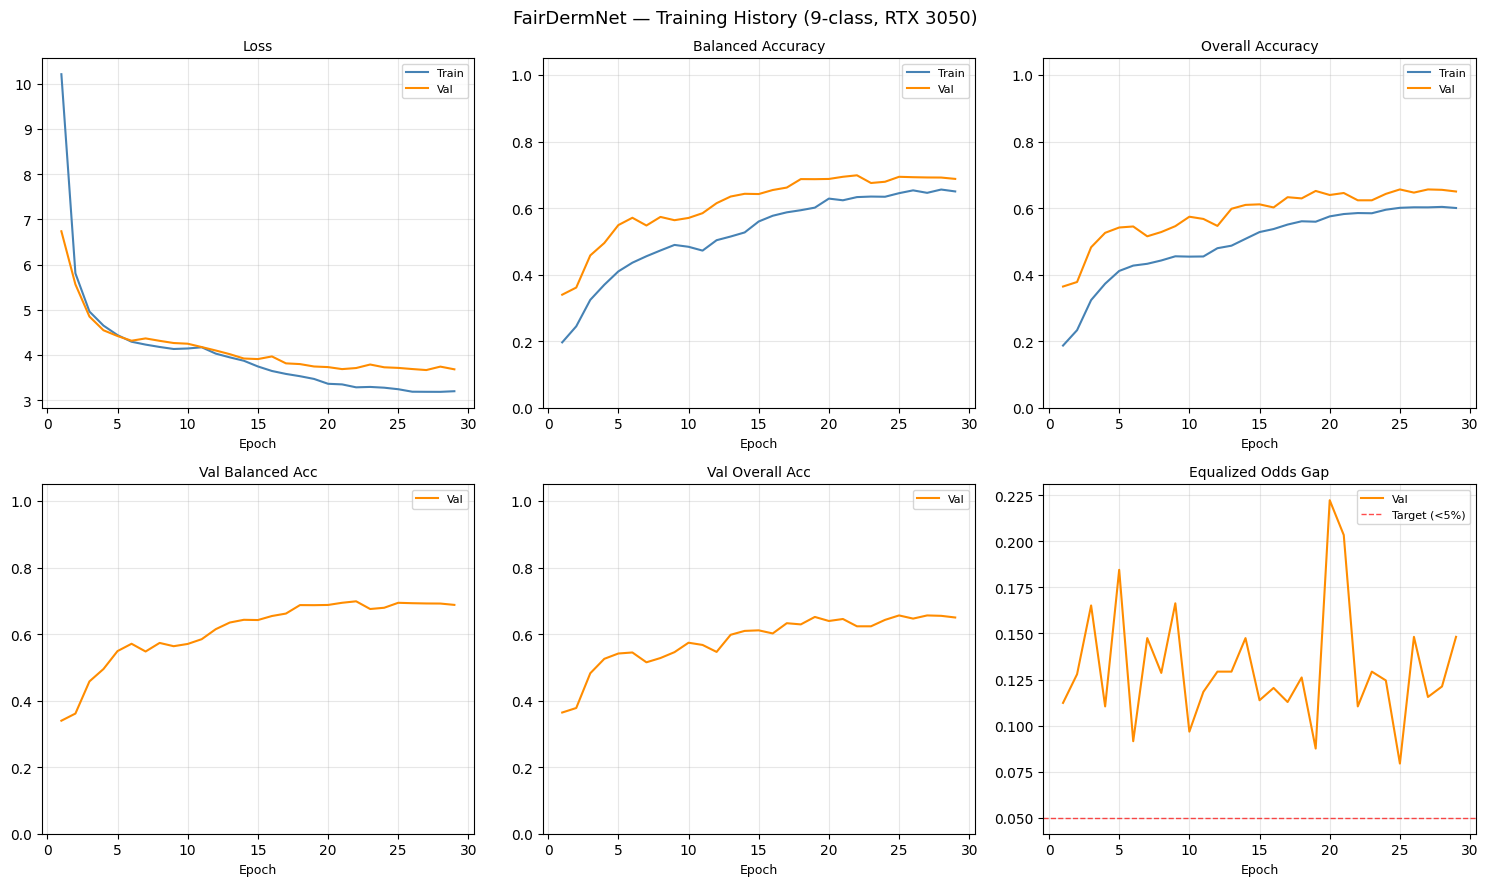

Saved: C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\figures/training_curves.png


In [12]:
import json
with open(CHECKPOINTS / "training_history.json", "w") as f:
    json.dump(history, f, indent=2)

epochs_x = [h["epoch"] for h in history]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle("FairDermNet — Training History (9-class, RTX 3050)", fontsize=13)
# Updated metric keys: balanced_accuracy replaces auc for 9-class
plots = [
    ("train_loss",              "val_loss",              "Loss",                0, 0),
    ("train_balanced_accuracy", "val_balanced_accuracy", "Balanced Accuracy",   0, 1),
    ("train_accuracy",          "val_accuracy",          "Overall Accuracy",    0, 2),
    (None,                      "val_balanced_accuracy", "Val Balanced Acc",    1, 0),
    (None,                      "val_accuracy",          "Val Overall Acc",     1, 1),
    (None,                      "val_fairness_gap",      "Equalized Odds Gap",  1, 2),
]
for train_key, val_key, title, r, c in plots:
    ax = axes[r, c]
    if train_key:
        ax.plot(epochs_x, [h[train_key] for h in history], label="Train", color="steelblue", linewidth=1.5)
    ax.plot(epochs_x, [h[val_key] for h in history], label="Val", color="darkorange", linewidth=1.5)
    if "gap" in val_key or "fairness" in val_key:
        ax.axhline(0.05, color="red", linestyle="--", linewidth=1, alpha=0.7, label="Target (<5%)")
    if "balanced_accuracy" in val_key or "accuracy" in val_key:
        ax.set_ylim(0, 1.05)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Epoch", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR}/training_curves.png")

### Cell 9 — Test set evaluation + fairness report

Loading best checkpoint for final evaluation...
[FairDermNet] Loaded weights from C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\checkpoints\best.pth


Evaluating:   0%|          | 0/263 [00:00<?, ?it/s]

Validation-calibrated threshold: 0.2518 (Validation sensitivity constraint (>=96%))
Validation AUC-ROC: 0.8876; threshold-config saved to C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\checkpoints\threshold_config.json


Evaluating:   0%|          | 0/255 [00:00<?, ?it/s]

  8-CLASS EVALUATION — TEST SET
  Overall accuracy:         61.85%
  Balanced accuracy:        63.25%
  (Balanced = mean per-class recall — fairer for imbalanced data)

  Per-class breakdown:
              precision    recall  f1-score   support

         MEL      0.513     0.658     0.576       647
         BCC      0.635     0.562     0.597       651
         SCC      0.177     0.454     0.255       108
          AK      0.414     0.453     0.433       256
          NV      0.927     0.659     0.771      1905
         BKL      0.461     0.557     0.504       422
          DF      0.180     0.789     0.293        38
        VASC      0.528     0.927     0.673        41

    accuracy                          0.618      4068
   macro avg      0.479     0.632     0.513      4068
weighted avg      0.703     0.618     0.644      4068


  Binary sensitivity (malignant detection): 84.66%
  Binary specificity:                       76.85%
  False negative rate:                      15.34%

  

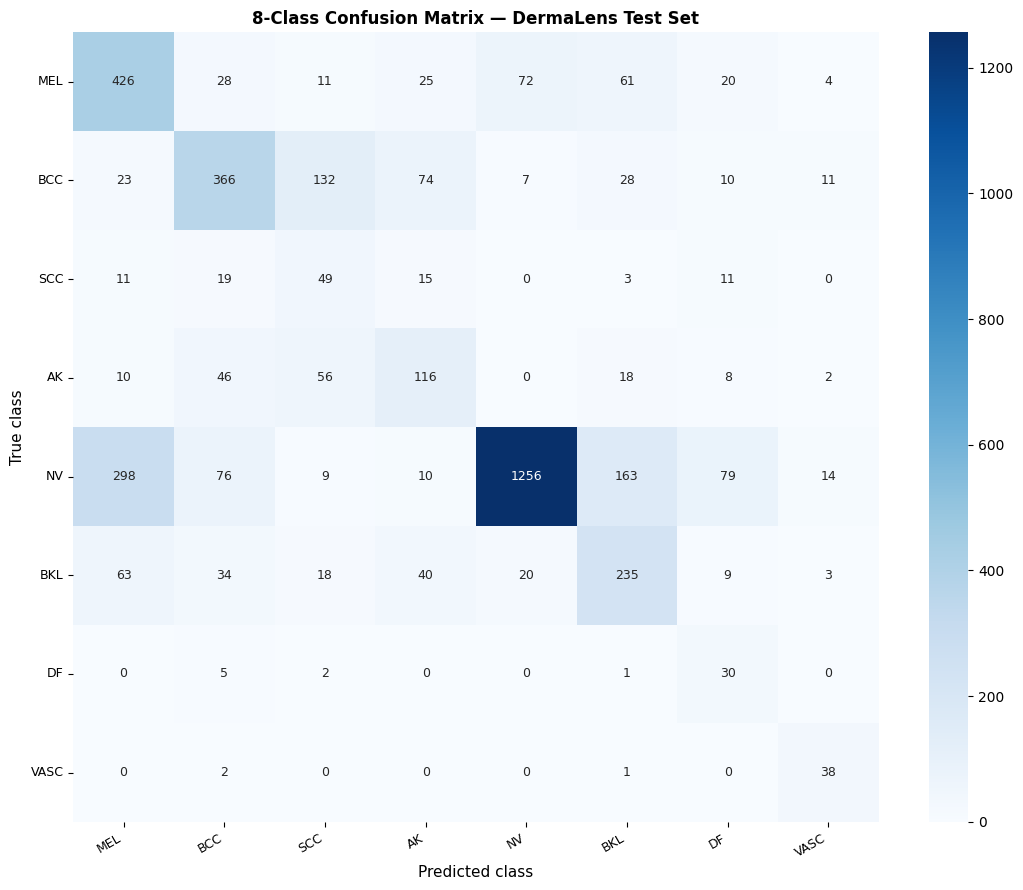

Saved: C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\figures/confusion_matrix_9class.png


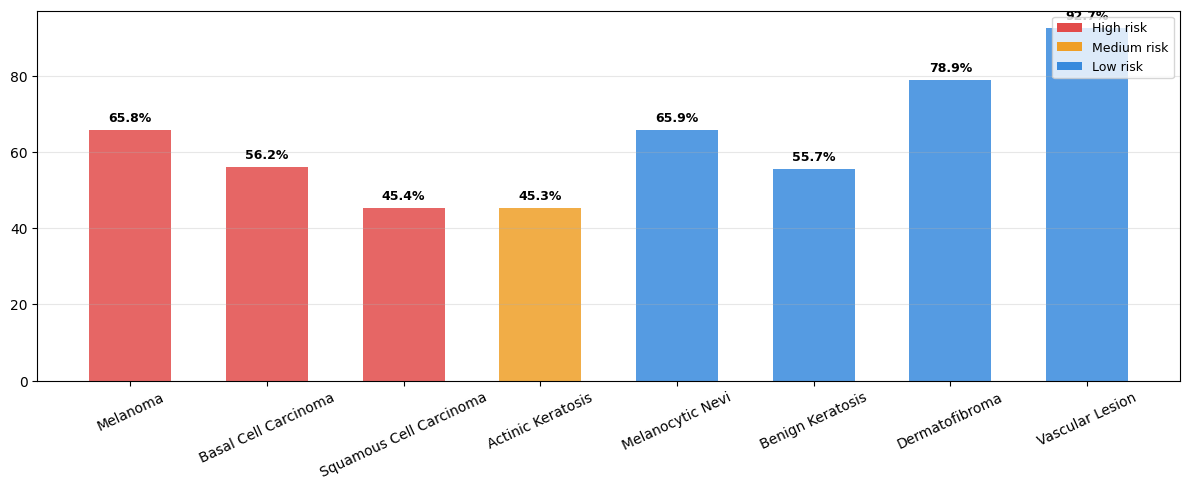

Saved: C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\figures/per_class_accuracy.png

Fairness report saved: C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\checkpoints\test_fairness_report.txt


In [13]:
import json
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, balanced_accuracy_score, roc_curve, auc
)
import seaborn as sns
from matplotlib.patches import Patch
from model.class_taxonomy import CLASS_NAMES, CLASS_SHORT, CLASS_RISK_TIER, MALIGNANT_CLASSES


def evaluate_multiclass(model, loader, device):
    """Run inference. Returns (true_classes, pred_classes, pred_probs [N, num_classes], skin_tones)."""
    model.eval()
    all_true, all_pred, all_probs, all_tones = [], [], [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            imgs   = batch["image"].to(device, non_blocking=True)
            logits = model(imgs)
            probs  = F.softmax(logits, dim=-1).cpu().numpy()
            preds  = np.argmax(probs, axis=1)
            all_true.extend(batch["class_idx"].numpy())
            all_pred.extend(preds)
            all_probs.extend(probs)
            all_tones.extend(batch["skin_tone"].numpy())
    return (np.array(all_true), np.array(all_pred),
            np.array(all_probs), np.array(all_tones))


print("Loading best checkpoint for final evaluation...")
best_model = FairDermNet.from_checkpoint(
    CHECKPOINTS / "best.pth",
    num_classes=NUM_CLASSES,
    num_skin_tones=len(FITZPATRICK_NAMES),
)
best_model.eval().to(DEVICE)

# Calibrate the binary operating threshold on validation data only. The test
# set remains untouched until the threshold has been fixed.
val_true_cls, val_pred_cls, val_pred_probs, val_eval_tones = evaluate_multiclass(
    best_model, val_loader, DEVICE
)
val_labels = np.array([1 if c in MALIGNANT_CLASSES else 0 for c in val_true_cls])
val_risk_probs = val_pred_probs[:, list(MALIGNANT_CLASSES)].sum(axis=1)
if np.unique(val_labels).size != 2:
    raise ValueError("Validation split must contain both binary risk groups to calibrate a threshold.")
val_fpr, val_tpr, val_thresholds = roc_curve(val_labels, val_risk_probs)
val_auc = auc(val_fpr, val_tpr)
clinical_mask = val_tpr >= 0.96
if clinical_mask.any():
    best_idx = np.where(clinical_mask)[0][np.argmin(val_fpr[clinical_mask])]
    optimal_threshold = float(val_thresholds[best_idx])
    threshold_method = "Validation sensitivity constraint (>=96%)"
else:
    best_idx = int(np.argmax(val_tpr - val_fpr))
    optimal_threshold = float(val_thresholds[best_idx])
    threshold_method = "Validation Youden's J fallback"
val_threshold_pred = (val_risk_probs >= optimal_threshold).astype(int)
val_tn, val_fp, val_fn, val_tp = confusion_matrix(
    val_labels, val_threshold_pred, labels=[0, 1]
).ravel()
threshold_config = {
    "default_threshold": 0.50,
    "clinical_threshold": round(optimal_threshold, 6),
    "sensitivity_at_clinical": round(float(val_tp / max(val_tp + val_fn, 1)), 4),
    "specificity_at_clinical": round(float(val_tn / max(val_tn + val_fp, 1)), 4),
    "roc_auc_validation": round(float(val_auc), 4),
    "calibration_split": "validation",
    "method": threshold_method,
}
with open(CHECKPOINTS / "threshold_config.json", "w") as f:
    json.dump(threshold_config, f, indent=2)
print(f"Validation-calibrated threshold: {optimal_threshold:.4f} ({threshold_method})")
print(f"Validation AUC-ROC: {val_auc:.4f}; threshold-config saved to {CHECKPOINTS / 'threshold_config.json'}")

# Final test evaluation uses the already-fixed validation threshold.
true_cls, pred_cls, pred_probs, eval_tones = evaluate_multiclass(
    best_model, test_loader, DEVICE
)

overall_acc  = accuracy_score(true_cls, pred_cls)
balanced_acc = balanced_accuracy_score(true_cls, pred_cls)

print("=" * 60)
print(f"  {NUM_CLASSES}-CLASS EVALUATION — TEST SET")
print("=" * 60)
print(f"  Overall accuracy:         {overall_acc*100:.2f}%")
print(f"  Balanced accuracy:        {balanced_acc*100:.2f}%")
print(f"  (Balanced = mean per-class recall — fairer for imbalanced data)")

present_classes = sorted(set(true_cls))
present_names   = [CLASS_SHORT[i] for i in present_classes]
print(f"\n  Per-class breakdown:")
print(classification_report(
    true_cls, pred_cls,
    labels=present_classes,
    target_names=present_names,
    digits=3, zero_division=0
))

# Binary sensitivity/specificity (for DDI comparison)
true_binary = np.array([1 if c in MALIGNANT_CLASSES else 0 for c in true_cls])
pred_binary = np.array([1 if c in MALIGNANT_CLASSES else 0 for c in pred_cls])
tp = int(((pred_binary==1)&(true_binary==1)).sum())
fn = int(((pred_binary==0)&(true_binary==1)).sum())
tn = int(((pred_binary==0)&(true_binary==0)).sum())
fp = int(((pred_binary==1)&(true_binary==0)).sum())
sens = tp / (tp + fn + 1e-8)
spec = tn / (tn + fp + 1e-8)
print(f"\n  Binary sensitivity (malignant detection): {sens*100:.2f}%")
print(f"  Binary specificity:                       {spec*100:.2f}%")
print(f"  False negative rate:                      {(1-sens)*100:.2f}%")

# Report test performance at the threshold selected on validation data.
test_risk_probs = pred_probs[:, list(MALIGNANT_CLASSES)].sum(axis=1)
test_threshold_pred = (test_risk_probs >= optimal_threshold).astype(int)
test_tn, test_fp, test_fn, test_tp = confusion_matrix(
    true_binary, test_threshold_pred, labels=[0, 1]
).ravel()
test_threshold_sens = test_tp / max(test_tp + test_fn, 1)
test_threshold_spec = test_tn / max(test_tn + test_fp, 1)
print(f"\n  Test metrics at fixed validation threshold ({optimal_threshold:.4f}):")
print(f"    Sensitivity: {test_threshold_sens*100:.2f}%")
print(f"    Specificity: {test_threshold_spec*100:.2f}%")
print(f"    Confusion counts (TN, FP, FN, TP): "
      f"{test_tn}, {test_fp}, {test_fn}, {test_tp}")

# ── Confusion matrix ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 9))
cm = confusion_matrix(true_cls, pred_cls, labels=present_classes)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", ax=ax,
    xticklabels=present_names, yticklabels=present_names,
    cbar=True, annot_kws={"size": 9}
)
ax.set_xlabel("Predicted class", fontsize=11)
ax.set_ylabel("True class", fontsize=11)
ax.set_title(f"{NUM_CLASSES}-Class Confusion Matrix — DermaLens Test Set",
             fontweight="bold", fontsize=12)
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_9class.png", dpi=150)
plt.show()
print(f"Saved: {FIGURES_DIR}/confusion_matrix_9class.png")

# ── Per-class accuracy bar chart ──────────────────────────────
per_class_acc = []
for i in present_classes:
    mask = true_cls == i
    acc  = float((pred_cls[mask] == i).mean()) if mask.sum() > 0 else 0.0
    per_class_acc.append((CLASS_NAMES[i], acc, CLASS_RISK_TIER[i]))

fig, ax = plt.subplots(figsize=(12, 5))
names  = [x[0] for x in per_class_acc]
accs   = [x[1] for x in per_class_acc]
tiers  = [x[2] for x in per_class_acc]
colors = ["#E24B4A" if t==2 else "#EF9F27" if t==1 else "#378ADD" for t in tiers]
bars   = ax.bar(names, [a*100 for a in accs], color=colors, alpha=0.85, width=0.6)
for bar, acc in zip(bars, accs):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
            f"{acc*100:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.tick_params(axis="x", rotation=25)
legend_elements = [
    Patch(facecolor="#E24B4A", label="High risk"),
    Patch(facecolor="#EF9F27", label="Medium risk"),
    Patch(facecolor="#378ADD", label="Low risk"),
]
ax.legend(handles=legend_elements, loc="upper right", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "per_class_accuracy.png", dpi=150)
plt.show()
print(f"Saved: {FIGURES_DIR}/per_class_accuracy.png")

fairness_metrics = compute_fairness_metrics(
    torch.tensor(pred_probs, dtype=torch.float32),
    torch.tensor(true_cls, dtype=torch.long),
    torch.tensor(eval_tones, dtype=torch.long),
    num_classes=NUM_CLASSES,
)
report = build_fairness_report(
    fairness_metrics,
    overall_accuracy=overall_acc,
    overall_balanced_accuracy=balanced_acc,
)

report_path = CHECKPOINTS / "test_fairness_report.txt"
with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print(f"\nFairness report saved: {report_path}")

### Cell 9b — DDI Fairness Evaluation

**Requires:** Cell 9 (test evaluation) or `checkpoints/best.pth` from a prior run. If run after a kernel restart, the cell will load the model from disk automatically.

DDI FAIRNESS EVALUATION (held-out, expert-labelled)
  Dataset: 656 samples


DDI evaluation:   0%|          | 0/41 [00:00<?, ?it/s]


DDI Overall Metrics:
  Accuracy:    52.44%
  AUC-ROC:     0.6272
  Sensitivity: 71.93%
  Specificity: 45.57%

DDI Per-Group Sensitivity (expert-labelled Fitzpatrick):
  FST I–II  (light): Sens=0.6939 | Spec=0.4717 | n=208
  FST III–IV (mid): Sens=0.7838 | Spec=0.5329 | n=241
  FST V–VI  (dark): Sens=0.6458 | Spec=0.3585 | n=207

  Equalized Odds Gap (DDI): 13.80%  ✗ Above target


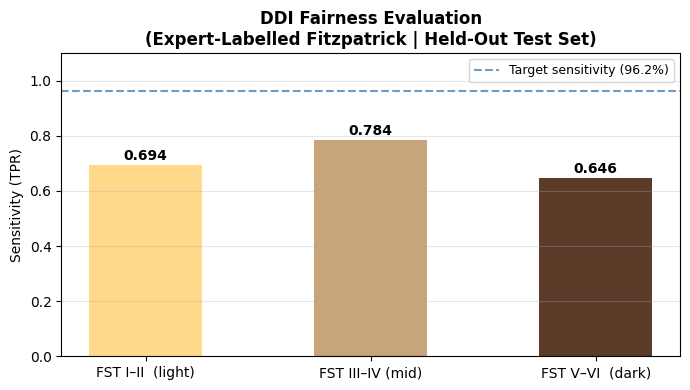


Saved: C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\figures/ddi_fairness_evaluation.png
  the gold-standard fairness benchmark in dermatology AI.

✓ DDI evaluation complete.
  This figure uses expert-labelled skin tone ground truth —


In [14]:
# Cell 9b — DDI Fairness Evaluation (held-out, expert-labelled)
# Requires: Cell 9 (loads best_model) OR checkpoints/best.pth from prior run
if 'ddi_df' not in globals():
    ddi_df = None

if ddi_df is None or len(ddi_df) == 0:
    print("ddi_df not available in this kernel session.")
    ddi_csv = DATASETS_DIR / "ddi_eval.csv"
    if ddi_csv.exists():
        ddi_df = pd.read_csv(ddi_csv)
        print(f"Loaded existing DDI eval table from {ddi_csv}")
    else:
        ddi_df = None

if ddi_df is None or len(ddi_df) == 0:
    print("DDI not available — skipping DDI fairness evaluation.")
    print("Download from: https://aimi.stanford.edu/datasets/ddi-diverse-dermatology-images")
else:
    # Ensure best_model is available (from Cell 9 or load from checkpoint)
    try:
        best_model
    except NameError:
        ckpt_path = CHECKPOINTS / "best.pth"
        if not ckpt_path.exists():
            raise RuntimeError(
                "best_model not found. Run Cell 9 first (Test set evaluation), or ensure "
                f"training has completed and {ckpt_path} exists."
            )
        print("Loading best checkpoint (Cell 9 not run — loading from disk)...")
        best_model = FairDermNet.from_checkpoint(
            ckpt_path,
            num_classes=NUM_CLASSES,
            num_skin_tones=len(FITZPATRICK_NAMES),
        )
        best_model.eval().to(DEVICE)

    print("=" * 58)
    print("DDI FAIRNESS EVALUATION (held-out, expert-labelled)")
    from model.class_taxonomy import MALIGNANT_CLASSES
    print("=" * 58)

    ddi_csv = DATASETS_DIR / "ddi_eval.csv"
    ddi_df.to_csv(ddi_csv, index=False)

    ddi_dataset = SkinLesionDataset(
        ddi_csv,
        transform=get_val_transforms(INPUT_SIZE),
        exclude_class_minus1=False,
    )
    ddi_loader = DataLoader(
        ddi_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,  # Windows spawn can't unpickle notebook-defined SkinLesionDataset
        pin_memory=PIN_MEMORY,
    )

    # --- Save TEST-SET binary counts under test_* names before the DDI block
    # below reuses tp/tn/fp/fn for its own per-group arithmetic (Cell 13 reads
    # the test-set numbers, so they must not be clobbered). ---
    test_tp, test_tn = tp, tn
    test_fp, test_fn = fp, fn
    test_sens, test_spec = sens, spec
    test_true_binary = true_binary

    ddi_preds, ddi_labels, ddi_tones = [], [], []
    with torch.no_grad():
        for batch in tqdm(ddi_loader, desc="DDI evaluation"):
            imgs = batch["image"].to(DEVICE, non_blocking=True)
            logits = best_model(imgs)
            probs = F.softmax(logits, dim=-1)[:, list(MALIGNANT_CLASSES)].sum(dim=-1).cpu().numpy()
            ddi_preds.extend(probs)
            ddi_labels.extend(batch["binary_label"].numpy())
            ddi_tones.extend(batch["skin_tone"].numpy())

    ddi_labels_arr = np.array(ddi_labels)
    ddi_preds_arr = np.array(ddi_preds)
    ddi_tones_arr = np.array(ddi_tones)

    y_pred_bin = (ddi_preds_arr >= 0.5).astype(int)
    tp = int(((y_pred_bin == 1) & (ddi_labels_arr == 1)).sum())
    tn = int(((y_pred_bin == 0) & (ddi_labels_arr == 0)).sum())
    fp = int(((y_pred_bin == 1) & (ddi_labels_arr == 0)).sum())
    fn = int(((y_pred_bin == 0) & (ddi_labels_arr == 1)).sum())

    from sklearn.metrics import roc_auc_score

    ddi_overall = {
        "accuracy": (tp + tn) / (len(ddi_labels_arr) + 1e-8),
        "auc": roc_auc_score(ddi_labels_arr, ddi_preds_arr),
        "sensitivity": tp / (tp + fn + 1e-8),
        "specificity": tn / (tn + fp + 1e-8),
    }

    print(f"\nDDI Overall Metrics:")
    print(f"  Accuracy:    {ddi_overall['accuracy']*100:.2f}%")
    print(f"  AUC-ROC:     {ddi_overall['auc']:.4f}")
    print(f"  Sensitivity: {ddi_overall['sensitivity']*100:.2f}%")
    print(f"  Specificity: {ddi_overall['specificity']*100:.2f}%")

    print(f"\nDDI Per-Group Sensitivity (expert-labelled Fitzpatrick):")
    GROUP_NAMES = {0: "FST I–II  (light)", 2: "FST III–IV (mid)", 4: "FST V–VI  (dark)"}
    group_sens = {}
    y_pred_bin = (ddi_preds_arr >= 0.5).astype(int)

    from sklearn.metrics import confusion_matrix
    for tone_idx, group_name in GROUP_NAMES.items():
        mask = ddi_tones_arr == tone_idx
        n = mask.sum()
        if n < 5:
            print(f"  {group_name}: insufficient samples (n={n})")
            continue
        cm = confusion_matrix(ddi_labels_arr[mask], y_pred_bin[mask], labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        sens = tp / (tp + fn + 1e-8)
        spec = tn / (tn + fp + 1e-8)
        group_sens[tone_idx] = sens
        print(f"  {group_name}: Sens={sens:.4f} | Spec={spec:.4f} | n={n}")

    if len(group_sens) >= 2:
        vals = list(group_sens.values())
        gap = max(vals) - min(vals)
        print(f"\n  Equalized Odds Gap (DDI): {gap*100:.2f}%  "
              f"{'✓ TARGET MET (<5%)' if gap < 0.05 else '✗ Above target'}")
    else:
        print("  Not enough groups to compute equalized odds gap.")

    labels_plot = [GROUP_NAMES[k] for k in sorted(group_sens.keys())]
    values_plot = [group_sens[k] for k in sorted(group_sens.keys())]
    colors_plot = ["#FFD580", "#C19A6B", "#4A2511"][:len(values_plot)]

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(labels_plot, values_plot, color=colors_plot, alpha=0.9, width=0.5)
    ax.axhline(0.962, color="steelblue", linestyle="--", linewidth=1.5,
               label="Target sensitivity (96.2%)", alpha=0.8)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
                f"{bar.get_height():.3f}", ha="center", va="bottom",
                fontsize=10, fontweight="bold")
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("Sensitivity (TPR)")
    ax.set_title("DDI Fairness Evaluation\n"
                 "(Expert-Labelled Fitzpatrick | Held-Out Test Set)", fontweight="bold")
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "ddi_fairness_evaluation.png", dpi=150)
    plt.show()

    print(f"\nSaved: {FIGURES_DIR}/ddi_fairness_evaluation.png")
    print("  the gold-standard fairness benchmark in dermatology AI.")

    print("\n✓ DDI evaluation complete.")
    print("  This figure uses expert-labelled skin tone ground truth —")

### Cell 9c — Validation-calibrated clinical threshold analysis

**Requires:** Cell 9 (test evaluation), which first selects `optimal_threshold` using validation predictions and applies that fixed value to the test set. This cell visualizes the validation ROC and threshold sweep; it does not use test labels to tune the threshold.


  THRESHOLD ANALYSIS
  Method: Validation sensitivity constraint (>=96%)
  Optimal threshold: 0.252
  At this threshold:
    Sensitivity (TPR):  96.06%
    Specificity (TNR):  38.01%
    False Negative Rate: 3.94%
    AUC-ROC:            0.8876

 Threshold  Sensitivity  Specificity      FNR      FPR       F1
--------------------------------------------------------------
      0.20        96.9%        24.0%     3.1%    76.0%    0.605
      0.25        96.2%        37.5%     3.8%    62.5%    0.646 ← optimal
      0.30        94.5%        50.4%     5.5%    49.6%    0.687
      0.35        92.4%        61.1%     7.6%    38.9%    0.723
      0.40        90.0%        68.7%    10.0%    31.3%    0.747
      0.45        86.5%        74.8%    13.5%    25.2%    0.760
      0.50        82.9%        79.7%    17.1%    20.3%    0.768
      0.55        79.2%        84.5%    20.8%    15.5%    0.775
      0.60        75.0%        87.0%    25.0%    13.0%    0.765
      0.65        70.5%        89.9%    2

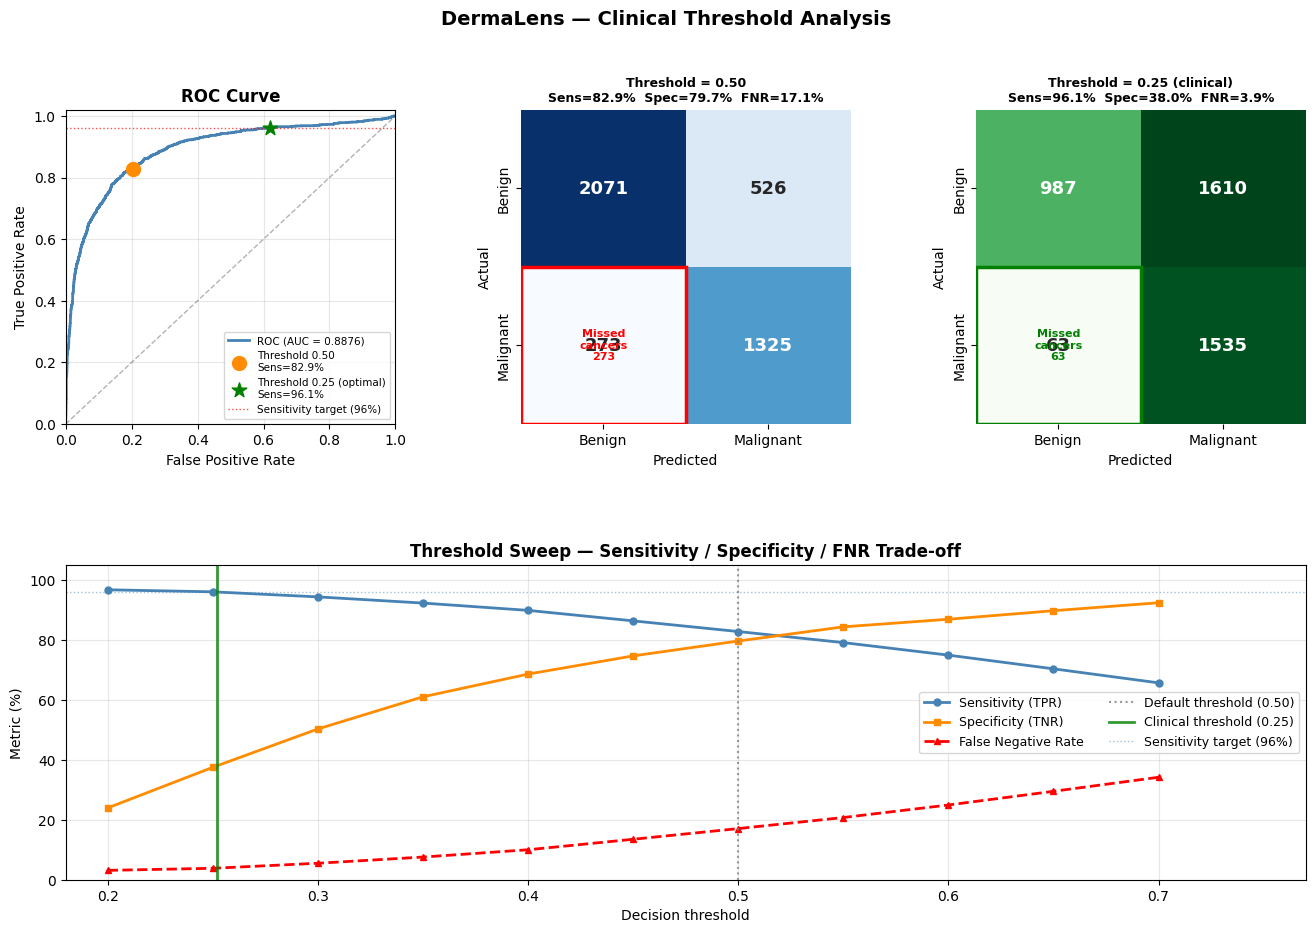


Saved: C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\figures/threshold_analysis.png

  VALIDATION THRESHOLD SUMMARY

Default threshold (0.50):
  Sensitivity:        82.9%
  Specificity:        79.7%
  False Negative Rate: 17.1%
  Missed cancers:     273 of 1598 malignant lesions

Clinical threshold (0.25):
  Sensitivity:        96.1%
  Specificity:        38.0%
  False Negative Rate: 3.9%
  Missed cancers:     63 of 1598 malignant lesions

Validation comparison only: these values describe threshold calibration data.
They are not final test performance estimates.


Threshold calibration used validation predictions only.
Final test sensitivity/specificity at this fixed threshold are reported in Cell 9.


In [15]:
# Cell 9c — Clinical Threshold Analysis (8-class compatible)
# Derives binary malignant probability from validation softmax output.
# Cell 9 calibrates and freezes optimal_threshold before final test evaluation.
try:
    val_true_cls
    val_pred_probs
    optimal_threshold
except NameError:
    raise RuntimeError("Run Cell 9 first to compute validation predictions and freeze the threshold.")

import numpy as np
import matplotlib.gridspec as gridspec
from sklearn.metrics import roc_curve, auc, confusion_matrix, f1_score

# Derive binary labels and risk probabilities from validation predictions.
# Malignant classes: 0-3 (MEL, BCC, SCC, AK).
from model.class_taxonomy import MALIGNANT_CLASSES
labels = np.array([1 if c in MALIGNANT_CLASSES else 0 for c in val_true_cls])
preds = val_pred_probs[:, list(MALIGNANT_CLASSES)].sum(axis=1)
fpr, tpr, thresholds = roc_curve(labels, preds)
roc_auc = auc(fpr, tpr)
optimal_sens = float(threshold_config["sensitivity_at_clinical"])
optimal_spec = float(threshold_config["specificity_at_clinical"])
method_used = threshold_config["method"]

print("=" * 56)
print("  THRESHOLD ANALYSIS")
print("=" * 56)
print(f"  Method: {method_used}")
print(f"  Optimal threshold: {optimal_threshold:.3f}")
print(f"  At this threshold:")
print(f"    Sensitivity (TPR):  {optimal_sens*100:.2f}%")
print(f"    Specificity (TNR):  {optimal_spec*100:.2f}%")
print(f"    False Negative Rate: {(1-optimal_sens)*100:.2f}%")
print(f"    AUC-ROC:            {roc_auc:.4f}")
print("=" * 56)

# STEP 2 — Threshold sweep table
sweep_thresholds = np.arange(0.20, 0.75, 0.05)
print(f"\n{'Threshold':>10} {'Sensitivity':>12} {'Specificity':>12} {'FNR':>8} {'FPR':>8} {'F1':>8}")
print("-" * 62)

sweep_results = []
for t in sweep_thresholds:
    y_pred_t = (preds >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, y_pred_t, labels=[0,1]).ravel()
    sens = tp / (tp + fn + 1e-8)
    spec = tn / (tn + fp + 1e-8)
    fnr  = fn / (tp + fn + 1e-8)
    fpr_ = fp / (tn + fp + 1e-8)
    f1   = f1_score(labels, y_pred_t, zero_division=0)
    sweep_results.append((t, sens, spec, fnr, fpr_, f1))
    marker = " ← optimal" if abs(t - optimal_threshold) < 0.03 else ""
    print(f"{t:>10.2f} {sens*100:>11.1f}% {spec*100:>11.1f}% {fnr*100:>7.1f}% {fpr_*100:>7.1f}% {f1:>8.3f}{marker}")

# STEP 3 — Confusion matrices
y_pred_050     = (preds >= 0.50).astype(int)
y_pred_optimal = (preds >= optimal_threshold).astype(int)
cm_050     = confusion_matrix(labels, y_pred_050,     labels=[0,1])
cm_optimal = confusion_matrix(labels, y_pred_optimal, labels=[0,1])

def cm_stats(cm):
    tn, fp, fn, tp = cm.ravel()
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "sens": tp / (tp + fn + 1e-8), "spec": tn / (tn + fp + 1e-8),
            "fnr": fn / (tp + fn + 1e-8), "acc": (tp + tn) / (tp + tn + fp + fn + 1e-8)}
s050  = cm_stats(cm_050)
s_opt = cm_stats(cm_optimal)

# STEP 4 — Figure
import seaborn as sns
fig = plt.figure(figsize=(16, 10))
fig.suptitle("DermaLens — Clinical Threshold Analysis", fontsize=14, fontweight="bold")
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.38)

ax_roc = fig.add_subplot(gs[0, 0])
ax_roc.plot(fpr, tpr, color="steelblue", linewidth=2, label=f"ROC (AUC = {roc_auc:.4f})")
ax_roc.plot([0,1],[0,1],"k--", alpha=0.3, linewidth=1)
idx_050 = np.argmin(np.abs(thresholds - 0.50))
ax_roc.scatter(fpr[idx_050], tpr[idx_050], s=100, color="darkorange", zorder=5, label=f"Threshold 0.50\nSens={tpr[idx_050]*100:.1f}%")
idx_opt = np.argmin(np.abs(thresholds - optimal_threshold))
ax_roc.scatter(fpr[idx_opt], tpr[idx_opt], s=120, color="green", marker="*", zorder=6, label=f"Threshold {optimal_threshold:.2f} (optimal)\nSens={tpr[idx_opt]*100:.1f}%")
ax_roc.axhline(0.96, color="red", linestyle=":", linewidth=1, alpha=0.7, label="Sensitivity target (96%)")
ax_roc.set_xlabel("False Positive Rate"); ax_roc.set_ylabel("True Positive Rate")
ax_roc.set_title("ROC Curve", fontweight="bold"); ax_roc.legend(loc="lower right", fontsize=7.5)
ax_roc.grid(alpha=0.3); ax_roc.set_xlim([0, 1]); ax_roc.set_ylim([0, 1.02])

ax_cm1 = fig.add_subplot(gs[0, 1])
sns.heatmap(cm_050, annot=True, fmt="d", cmap="Blues", ax=ax_cm1,
            xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"],
            cbar=False, annot_kws={"size": 13, "weight": "bold"})
ax_cm1.set_xlabel("Predicted"); ax_cm1.set_ylabel("Actual")
ax_cm1.set_title(f"Threshold = 0.50\nSens={s050['sens']*100:.1f}%  Spec={s050['spec']*100:.1f}%  FNR={s050['fnr']*100:.1f}%", fontsize=9, fontweight="bold")
ax_cm1.add_patch(plt.Rectangle((0, 1), 1, 1, fill=False, edgecolor="red", lw=2.5))
ax_cm1.text(0.5, 1.5, f"Missed\ncancers\n{cm_050[1,0]}", ha="center", va="center", fontsize=8, color="red", fontweight="bold")

ax_cm2 = fig.add_subplot(gs[0, 2])
sns.heatmap(cm_optimal, annot=True, fmt="d", cmap="Greens", ax=ax_cm2,
            xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"],
            cbar=False, annot_kws={"size": 13, "weight": "bold"})
ax_cm2.set_xlabel("Predicted"); ax_cm2.set_ylabel("Actual")
ax_cm2.set_title(f"Threshold = {optimal_threshold:.2f} (clinical)\nSens={s_opt['sens']*100:.1f}%  Spec={s_opt['spec']*100:.1f}%  FNR={s_opt['fnr']*100:.1f}%", fontsize=9, fontweight="bold")
ax_cm2.add_patch(plt.Rectangle((0, 1), 1, 1, fill=False, edgecolor="green", lw=2.5))
ax_cm2.text(0.5, 1.5, f"Missed\ncancers\n{cm_optimal[1,0]}", ha="center", va="center", fontsize=8, color="green", fontweight="bold")

ax_sweep = fig.add_subplot(gs[1, :])
ts = [r[0] for r in sweep_results]
ax_sweep.plot(ts, [r[1]*100 for r in sweep_results], "steelblue", linewidth=2, marker="o", ms=5, label="Sensitivity (TPR)")
ax_sweep.plot(ts, [r[2]*100 for r in sweep_results], "darkorange", linewidth=2, marker="s", ms=5, label="Specificity (TNR)")
ax_sweep.plot(ts, [r[3]*100 for r in sweep_results], "red", linewidth=2, marker="^", ms=5, linestyle="--", label="False Negative Rate")
ax_sweep.axvline(0.50, color="gray", linestyle=":", linewidth=1.5, alpha=0.8, label="Default threshold (0.50)")
ax_sweep.axvline(optimal_threshold, color="green", linestyle="-", linewidth=2, alpha=0.8, label=f"Clinical threshold ({optimal_threshold:.2f})")
ax_sweep.axhline(96, color="steelblue", linestyle=":", linewidth=1, alpha=0.5, label="Sensitivity target (96%)")
ax_sweep.set_xlabel("Decision threshold"); ax_sweep.set_ylabel("Metric (%)")
ax_sweep.set_title("Threshold Sweep — Sensitivity / Specificity / FNR Trade-off", fontweight="bold")
ax_sweep.legend(loc="center right", fontsize=9, ncol=2); ax_sweep.grid(alpha=0.3)
ax_sweep.set_xlim([0.18, 0.77]); ax_sweep.set_ylim([0, 105])

plt.savefig(FIGURES_DIR / "threshold_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"\nSaved: {FIGURES_DIR}/threshold_analysis.png")

# STEP 5 — Report summary
missed_050 = int(cm_050[1, 0]); missed_opt = int(cm_optimal[1, 0]); reduction = missed_050 - missed_opt
print("\n" + "=" * 56)
print("  VALIDATION THRESHOLD SUMMARY")
print("=" * 56)
print(f"""
Default threshold (0.50):
  Sensitivity:        {s050['sens']*100:.1f}%
  Specificity:        {s050['spec']*100:.1f}%
  False Negative Rate: {s050['fnr']*100:.1f}%
  Missed cancers:     {missed_050} of {int(labels.sum())} malignant lesions

Clinical threshold ({optimal_threshold:.2f}):
  Sensitivity:        {s_opt['sens']*100:.1f}%
  Specificity:        {s_opt['spec']*100:.1f}%
  False Negative Rate: {s_opt['fnr']*100:.1f}%
  Missed cancers:     {missed_opt} of {int(labels.sum())} malignant lesions

Validation comparison only: these values describe threshold calibration data.
They are not final test performance estimates.
""")
print("=" * 56)

# The fixed threshold and validation calibration metadata were saved in Cell 9.
print("\nThreshold calibration used validation predictions only.")
print("Final test sensitivity/specificity at this fixed threshold are reported in Cell 9.")


### Cell 10 — Fairness bar charts (per-Fitzpatrick group)

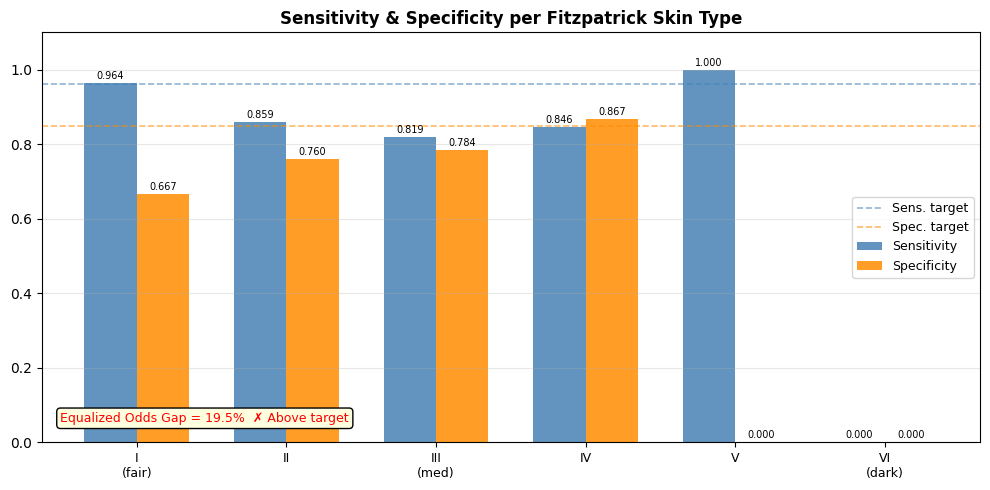

Saved: C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\figures/fairness_by_skin_type.png


In [16]:
FITZ_SHORT = ["I\n(fair)", "II", "III\n(med)", "IV", "V", "VI\n(dark)"]
FITZ_COLORS = ["#FFE4C4","#FFDEAD","#D2B48C","#C19A6B","#8B6914","#4A2511"]

# Cell 9's fairness breakdown lives in `fairness_metrics["group_metrics"]`
# (int key -> {accuracy/sensitivity/specificity as fractions}). The old
# `report.per_group_sensitivity` dot-access never existed — report is a plain
# dict with "per_group" rows in percent.
gm = fairness_metrics.get("group_metrics", {}) if "fairness_metrics" in globals() else {}

if not gm:
    print("No per-group fairness data available — run Cell 9 (Test set evaluation) first. Skipping chart.")
else:
    sens_vals = [gm.get(t, {}).get("sensitivity", 0) for t in range(6)]
    spec_vals = [gm.get(t, {}).get("specificity", 0) for t in range(6)]
    x = np.arange(6)
    w = 0.35
    fig, ax = plt.subplots(figsize=(10, 5))
    bars1 = ax.bar(x - w/2, sens_vals, w, label="Sensitivity", color="steelblue", alpha=0.85)
    bars2 = ax.bar(x + w/2, spec_vals, w, label="Specificity", color="darkorange", alpha=0.85)
    ax.axhline(0.962, color="steelblue", linestyle="--", alpha=0.6, linewidth=1.2, label="Sens. target")
    ax.axhline(0.850, color="darkorange", linestyle="--", alpha=0.6, linewidth=1.2, label="Spec. target")
    for bar in [*bars1, *bars2]:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=7)
    eo_gap = fairness_metrics.get("equalized_odds_gap", 0)
    ax.annotate(f"Equalized Odds Gap = {eo_gap*100:.1f}%  {'✓ TARGET MET' if eo_gap < 0.05 else '✗ Above target'}", xy=(0.02, 0.05), xycoords="axes fraction", fontsize=9, color="green" if eo_gap < 0.05 else "red", bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow"))
    ax.set_xticks(x)
    ax.set_xticklabels(FITZ_SHORT, fontsize=9)
    ax.set_ylim(0, 1.1)
    ax.set_title("Sensitivity & Specificity per Fitzpatrick Skin Type", fontweight="bold")
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fairness_by_skin_type.png", dpi=150)
    plt.show()
    print(f"Saved: {FIGURES_DIR}/fairness_by_skin_type.png")


### Cell 11 — GradCAM++ on 3 test samples

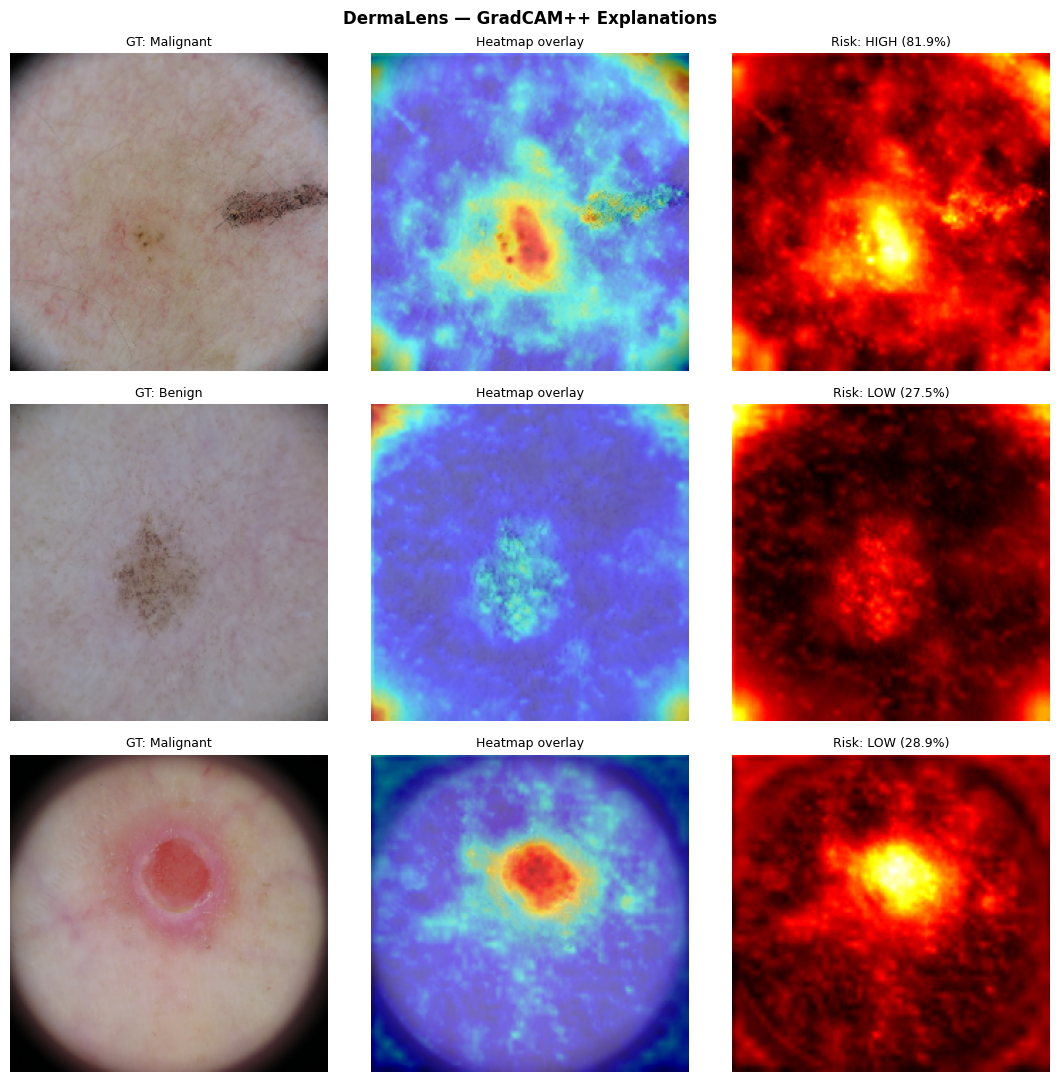

In [17]:
torch.cuda.empty_cache(); gc.collect()
import numpy as np
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
target_layer = best_model.get_gradcam_target_layer()
cam_gen = GradCAMPlusPlus(best_model, target_layer)
transform = get_val_transforms(INPUT_SIZE)
test_df_ = pd.read_csv(DATASETS_DIR / "split_test.csv")
samples = test_df_.sample(3, random_state=99).reset_index(drop=True)
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
fig.suptitle("DermaLens — GradCAM++ Explanations", fontweight="bold")
for i, (_, row) in enumerate(samples.iterrows()):
    img_bgr = cv2.imread(row["image_path"])
    if img_bgr is None:
        continue
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_rgb_224 = cv2.resize(img_rgb, (224, 224))
    tensor = transform(image=img_rgb_224)["image"].unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        best_model.eval()
        prob = float(F.softmax(best_model(tensor), dim=-1)[0, list(MALIGNANT_CLASSES)].sum())
    # squeeze batch dim: CAMs come back as (1, H, W); OpenCV colormap wants 2-D
    heatmap = np.squeeze(cam_gen(tensor, targets=[ClassifierOutputTarget(1)]))
    hm_norm = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    overlay = show_cam_on_image(img_rgb_224 / 255.0, hm_norm.astype("float32"), use_rgb=True, image_weight=0.55)
    risk = "HIGH" if prob > 0.7 else "MED" if prob > 0.3 else "LOW"
    gt = "Malignant" if class_idx_to_binary(int(row["class_idx"])) == 1 else "Benign"
    axes[i, 0].imshow(img_rgb_224)
    axes[i, 0].set_title(f"GT: {gt}", fontsize=9)
    axes[i, 0].axis("off")
    axes[i, 1].imshow(overlay)
    axes[i, 1].set_title("Heatmap overlay", fontsize=9)
    axes[i, 1].axis("off")
    axes[i, 2].imshow(heatmap, cmap="hot")
    axes[i, 2].set_title(f"Risk: {risk} ({prob*100:.1f}%)", fontsize=9)
    axes[i, 2].axis("off")
cam_gen.activations_and_grads.release()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "gradcam_examples.png", dpi=150)
plt.show()

### Cell 12 — Export ONNX + TFLite

In [18]:
from export.onnx_export import export_to_onnx
from export.quantize_tflite import convert_onnx_to_tflite, benchmark_tflite

EXPORT_DIR = PROJECT_ROOT / "export"
EXPORT_DIR.mkdir(exist_ok=True)

onnx_path = export_to_onnx(best_model, output_path=EXPORT_DIR / "fairdermnet.onnx", input_size=224, opset_version=11, simplify=True)
onnx_mb = onnx_path.stat().st_size / 1e6
print(f"ONNX: {onnx_mb:.2f} MB")

try:
    tflite_path = convert_onnx_to_tflite(onnx_path=onnx_path, output_path=EXPORT_DIR / "fairdermnet_int8.tflite", num_calibration_samples=200, quantize_int8=True)
    tflite_mb = tflite_path.stat().st_size / 1e6
    print(f"TFLite INT8: {tflite_mb:.2f} MB  {'✓' if tflite_mb < 6.0 else '✗'} target <6 MB")
except Exception as e:
    print(f"TFLite conversion failed (onnx-tf may be missing): {e}")
    tflite_mb = None

[ONNX Export] Tracing model with input (1, 3, 224, 224) ...


C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\model\fairdermet.py:198: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if self.training or return_aux:


[ONNX Export] ✓ Saved → C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\export\fairdermnet.onnx  (20.66 MB)
[ONNX Export] ⚠ onnxsim not installed — skipping simplification.
              pip install onnxsim
ONNX: 20.66 MB


c:\Users\sanja\AppData\Local\Programs\Python\Python310\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


[Export] Loading ONNX from C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\export\fairdermnet.onnx ...
[Export] Exporting to TF SavedModel at C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\export\_tmp_saved_model ...
INFO:tensorflow:Assets written to: C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\export\_tmp_saved_model\assets


INFO:tensorflow:Assets written to: C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\export\_tmp_saved_model\assets


[Export] Converting SavedModel → TFLite ...
[Export] ✓ TFLite written → C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\export\fairdermnet_int8.tflite  (5.51 MB)
[Export]   Mode: dynamic-range quantization (int8 weights, float32 activations).
[Export]   Full INT8 is avoided — GeM power op is unquantizable (see docstring).
TFLite INT8: 5.51 MB  ✓ target <6 MB


### Cell 13 — Final summary

In [19]:
best_epoch = max(history, key=lambda h: h["val_balanced_accuracy"])
from sklearn.metrics import roc_auc_score

# Recompute summary metrics from the TEST-SET variables (Cell 9). Cell 9b
# reuses the bare names tp/tn/fp/fn for DDI counts, so never trust them here.
tp, fp, fn, tn = test_tp, test_fp, test_fn, test_tn
sens = tp / (tp + fn + 1e-8)
spec = tn / (tn + fp + 1e-8)
f1 = 2 * tp / (2 * tp + fp + fn + 1e-8)
try:
    auc = roc_auc_score(test_true_binary, pred_probs[:, list(MALIGNANT_CLASSES)].sum(axis=1))
except Exception:
    auc = float("nan")
gp = report.get("per_group", [])
perf_parity = (max(r["accuracy"] for r in gp) - min(r["accuracy"] for r in gp)) if len(gp) >= 2 else 0.0
print("\n" + "="*60)
print("DERMALENS FAIRDERMET — FINAL SUMMARY")
print("Cambridge Institute of Technology | 2026-27")
print("="*60)
print(f"  Best epoch:         {best_epoch['epoch']}")
print(f"  Overall Accuracy:   {report.get('overall_accuracy_pct', overall_acc*100):.2f}%")
print(f"  Balanced Accuracy:  {report.get('overall_balanced_accuracy_pct', balanced_acc*100):.2f}%")
print(f"  AUC-ROC (binary):   {auc:.4f}")
print(f"  Sensitivity (TPR):  {sens*100:.2f}%")
print(f"  Specificity (TNR):  {spec*100:.2f}%")
print(f"  F1 (malignant):     {f1*100:.2f}%")
print("-"*60)
print(f"  Equalized Odds Gap: {report.get('equalized_odds_gap_pct', 0.0):.2f}%  {'✓' if report.get('fairness_target_met') else '✗ (target: <5%)'}")
print(f"  Performance Parity: {perf_parity:.2f}%")
print("-"*60)
try:
    print(f"  ONNX size:          {onnx_mb:.2f} MB")
    if tflite_mb is None:
        print("  TFLite size:        n/a (conversion failed — see Cell 12 log)")
    else:
        print(f"  TFLite size:        {tflite_mb:.2f} MB  {'✓' if tflite_mb < 6.0 else '✗'}")
except NameError:
    print("  (Run Cell 12 to see export sizes)")
print("="*60)
print("\n✓ Notebook complete.")
print(f"   TFLite model → copy to Flutter app:")
print(f"   {EXPORT_DIR / 'fairdermnet_int8.tflite'}")


DERMALENS FAIRDERMET — FINAL SUMMARY
Cambridge Institute of Technology | 2026-27
  Best epoch:         22
  Overall Accuracy:   61.85%
  Balanced Accuracy:  63.25%
  AUC-ROC (binary):   0.9009
  Sensitivity (TPR):  84.66%
  Specificity (TNR):  76.85%
  F1 (malignant):     77.61%
------------------------------------------------------------
  Equalized Odds Gap: 19.45%  ✗ (target: <5%)
  Performance Parity: 12.24%
------------------------------------------------------------
  ONNX size:          20.66 MB
  TFLite size:        5.51 MB  ✓

✓ Notebook complete.
   TFLite model → copy to Flutter app:
   C:\Users\sanja\Documents\sanjana\CAMBRIDGE\final year project\model\export\fairdermnet_int8.tflite
